# Práctica DL para Finanzas — Avance 3 (Capítulo 9)
**Validación temporal, umbrales de pronóstico y señales**

| Campo | Valor |
|---|---|
| Equipo | _Figueroa Manríquez Elizabeth Priscilla_ |
| Activo | BTC/USDT diario, MEXC spot (mismo archivo crudo de los avances 1 y 2) |
| Objetivo | Pronóstico de **un periodo**: $y_t = P_{t+1}/P_t - 1$ |
| Modelos | Red profunda que continuó del Avance 2 (MLP y LSTM con su mejor configuración) y regresión lineal como referencia |

Requisitos del Avance 3 que cubre este notebook:
1. **Tres evaluaciones con ventana expansiva dentro de TR.** Cada entrenamiento termina antes del bloque que evalúa, y los escaladores se reajustan solo con ese entrenamiento. Se reporta el error de cada ventana.
2. **VA se conserva para la selección final y TE queda reservado.**
3. **Pronóstico de un periodo** (obligatorio). El pronóstico directo y recursivo de varios periodos es una ampliación opcional y no se implementa.
4. **Hasta cinco umbrales candidatos**, definidos con TR antes de mirar VA. En VA se elige uno: comprar si el rendimiento estimado supera δ; si no, quedarse en efectivo. La simulación sigue las reglas del protocolo: capital de 100,000 USDT, costo de 0.10% por compra y por venta, y ejecución en la apertura de t+1.
5. **Diferenciación fraccionaria:** propósito y pertinencia, con una prueba opcional sobre TR.
6. **Comprobación de que TE no intervino en ninguna decisión.**

**Antes de ejecutar:**
1. Activen la GPU T4: `Entorno de ejecución → Cambiar tipo de entorno → GPU T4`. Las ventanas expansivas reentrenan las redes.
2. Deben existir en Drive los resultados del Avance 2: `resultados/seleccion_cap8.json`, `resultados/busqueda_configuraciones_cap8.csv` y los modelos en `modelos/cap8/`.
3. `Entorno de ejecución → Ejecutar todas`.

## 0. Entorno, configuración, versiones y bitácora

In [1]:
# === 0.1 Montar Drive y crear carpetas persistentes ===
import os, sys, json, time, random, hashlib, platform, subprocess, warnings
from datetime import datetime, timezone
from pathlib import Path

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/DL_Finanzas')
else:
    BASE = Path(os.environ.get('DL_FIN_BASE', './DL_Finanzas'))

DIRS = {k: BASE / v for k, v in {
    'crudos': 'datos/originales',
    'procesados': 'datos/procesados',
    'modelos': 'modelos',
    'resultados': 'resultados',
    'figuras': 'figuras',
    'evidencia': 'evidencia_t4',
    'bitacora': 'bitacora',
}.items()}
for carpeta in DIRS.values():
    carpeta.mkdir(parents=True, exist_ok=True)
print('En Colab:', EN_COLAB)
print('Carpeta del proyecto:', BASE.resolve())

Mounted at /content/drive
En Colab: True
Carpeta del proyecto: /content/drive/MyDrive/DL_Finanzas


In [2]:
# === 0.2 Librerías, configuración, semilla y versiones ===
import numpy as np
import pandas as pd
import requests, joblib, sklearn, matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

CONFIG = {
    # --- Datos y partición: idénticos al Avance 1 ---
    'MERCADO': 'Criptomonedas',
    'SIMBOLO': 'BTCUSDT',
    'MONEDA_BASE': 'BTC',
    'MONEDA_COTIZADA': 'USDT',
    'INTERVALO': '1d',
    'FUENTE': 'MEXC Spot API v3, endpoint público GET /api/v3/klines',
    'URL_KLINES': 'https://api.mexc.com/api/v3/klines',
    'INICIO_DESCARGA_UTC': '2017-01-01',
    'REUTILIZAR_CRUDO': True,      # usa el mismo crudo del Avance 1 (mismas fechas TR/VA/TE)
    'ARCHIVO_LOCAL': None,
    'MIN_OBS': 1500,
    'HUECO_MAX_DIAS': 7,
    'N_REZAGOS': 20,
    'PROP_TR': 0.70,
    'PROP_VA': 0.15,
    'SEMILLA': 42,
    # --- Redes del capítulo 8 ---
    'REQUIERE_T4': True,           # si no hay T4, se detiene el entrenamiento profundo (regla del protocolo)
    'PERDIDA': 'mean_squared_error',   # como en el libro
    'OPTIMIZADOR': 'Adam',             # como en el libro
    'TASA_APRENDIZAJE': 1e-3,
    'LOTE': 32,                    # el libro sugiere empezar con 32
    'MAX_EPOCAS': 300,
    'PACIENCIA': 25,               # épocas sin mejorar la pérdida de VA antes de detener
    'NEURONAS_CANDIDATAS': [10, 20, 40],   # 20 = configuración del libro; solo cambia el número de neuronas
    'SEMILLAS': [42, 123, 2024],   # repetición de la mejor configuración de cada red
    # --- Capítulo 9 ---
    'CV_VENTANAS': 3,              # evaluaciones con ventana expansiva dentro de TR
    'CV_INICIO': 0.50,             # el primer entrenamiento usa el primer 50 % de TR; el resto se divide en 3 bloques
    'CV_VAL_INTERNA': 0.15,        # último 15 % de cada entrenamiento: solo para la parada temprana
    'REDES_CV': ['lstm', 'mlp'],   # redes que se reentrenan en cada ventana (mejor configuración del Avance 2)
    'CUANTILES_UMBRAL': [0.10, 0.25, 0.50, 0.75, 0.90],  # umbrales = cuantiles de las predicciones del modelo en TR
    'UMBRALES_RESPALDO': [0.0005, 0.001, 0.002, 0.003, 0.005],  # solo si el modelo no tiene predicciones positivas en TR
    'CAPITAL_INICIAL': 100_000,    # USDT
    'COSTO': 0.001,                # 0.10 % por compra y por venta (supuesto académico)
    'FRACDIFF_OPCIONAL': True,     # prueba opcional de diferenciación fraccionaria (solo TR)
}
SEMILLA = CONFIG['SEMILLA']
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ['PYTHONHASHSEED'] = str(SEMILLA)

import tensorflow as tf
import keras
from keras import layers
info_build = tf.sysconfig.get_build_info()
VERSIONES = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'cuda_build': info_build.get('cuda_version', 'n/d'),
    'cudnn_build': info_build.get('cudnn_version', 'n/d'),
    'plataforma': platform.platform(),
    'semilla_base': SEMILLA,
    'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS['resultados'] / 'versiones_entorno_cap9.json', 'w') as f:
    json.dump(VERSIONES, f, indent=2)
pd.Series(VERSIONES)

,0
python,3.13.16
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
tensorflow,2.21.0
keras,3.13.2
cuda_build,12.5.1
cudnn_build,9
plataforma,Linux-6.6.159+-x86_64-with-glibc2.39


In [3]:
# === 0.3 Excepciones específicas y bitácora de errores ===
# Regla: nada de "except: pass". Cada error se captura por tipo, se explica y se registra.
class ErrorPractica(Exception):
    'Error base de la práctica.'
class DescargaError(ErrorPractica):
    'La fuente no respondió o respondió con un error.'
class DatosVaciosError(ErrorPractica):
    'No hay datos, o no alcanzan el mínimo requerido.'
class FechaDuplicadaError(ErrorPractica):
    'Fechas repetidas que no se pueden resolver con la regla documentada.'
class ValorInvalidoError(ErrorPractica):
    'Valores no finitos, no positivos o archivo alterado.'
class DimensionError(ErrorPractica):
    'Formas o columnas distintas a las esperadas.'
class FugaInformacionError(ErrorPractica):
    'Se detectó uso de información futura o del conjunto reservado.'

RUTA_BITACORA = DIRS['bitacora'] / 'bitacora_errores.csv'

def registrar_evento(etapa, error, causa, accion, verificacion):
    'Agrega una fila: fecha | etapa | error | causa | acción correctiva | resultado de la verificación.'
    fila = pd.DataFrame([{
        'fecha': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'etapa': etapa, 'error': error, 'causa': causa,
        'accion_correctiva': accion, 'resultado_verificacion': verificacion,
    }])
    fila.to_csv(RUTA_BITACORA, mode='a', header=not RUTA_BITACORA.exists(), index=False)
    print(f'[BITÁCORA] {etapa} | {error} | {causa} | {accion} | {verificacion}')

In [4]:
# === 0.4 Excepciones adicionales del capítulo 8 ===
class ParticionDistintaError(ErrorPractica):
    'Las particiones no coinciden con las del Avance 1.'
class EntrenamientoError(ErrorPractica):
    'Fallo del entrenamiento (pérdida no finita, pesos no restaurados, GPU no usada).'

## 1. Evidencia de la GPU T4

In [5]:
# === 1. Evidencia de T4 ===
def verificar_t4():
    ts = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    ev = {'fecha_utc': ts, 'entorno_colab': EN_COLAB, 'semilla': SEMILLA}

    # 1) nvidia-smi
    try:
        salida = subprocess.run(['nvidia-smi'], capture_output=True, text=True,
                                timeout=30, check=True).stdout
        print(salida)
        (DIRS['evidencia'] / f'nvidia_smi_{ts}.txt').write_text(salida)
        consulta = subprocess.run(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            capture_output=True, text=True, timeout=30, check=True).stdout.strip()
        ev['nvidia_smi_gpu'] = consulta
    except FileNotFoundError:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no existe: el entorno no tiene GPU NVIDIA'
    except subprocess.CalledProcessError as e:
        ev['nvidia_smi_gpu'] = f'nvidia-smi falló: {e.stderr.strip()}'
    except subprocess.TimeoutExpired:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no respondió en 30 s'

    # 2) y 3) TensorFlow reconoce la GPU y ejecuta una operación en ella
    import tensorflow as tf
    tf.random.set_seed(SEMILLA)
    ev['tensorflow'] = tf.__version__
    ev['tf_construido_con_cuda'] = bool(tf.test.is_built_with_cuda())
    gpus = tf.config.list_physical_devices('GPU')
    ev['tf_gpus'] = [g.name for g in gpus]
    ev['operacion_dispositivo'] = 'sin GPU'
    if gpus:
        detalles = tf.config.experimental.get_device_details(gpus[0])
        ev['tf_nombre_gpu'] = detalles.get('device_name', '')
        ev['compute_capability'] = str(detalles.get('compute_capability', ''))
        with tf.device('/GPU:0'):
            a = tf.random.normal((4000, 4000))
            _ = tf.matmul(a, a).numpy()            # calentamiento
            t0 = time.perf_counter()
            c = tf.matmul(a, a)
            _ = c.numpy()                          # fuerza la sincronización
            ev['matmul_4000x4000_s'] = round(time.perf_counter() - t0, 4)
        ev['operacion_dispositivo'] = c.device
    nombre = f"{ev.get('tf_nombre_gpu', '')} {ev.get('nvidia_smi_gpu', '')}"
    ev['T4_OK'] = ('T4' in nombre) and ('GPU' in ev['operacion_dispositivo'])

    with open(DIRS['evidencia'] / f'evidencia_t4_{ts}.json', 'w') as f:
        json.dump(ev, f, indent=2)
    if not ev['T4_OK']:
        registrar_evento('entorno', 'T4 ausente o GPU no utilizada',
                         f"GPU detectada: {nombre.strip() or 'ninguna'}",
                         'Cap. 7 continúa en CPU (modelos clásicos). No entrenar MLP/LSTM; reprogramar sesión con T4.',
                         'pendiente')
    return ev

EVIDENCIA_T4 = verificar_t4()
print(json.dumps(EVIDENCIA_T4, indent=2))
print('\n>>> T4 verificada y usada por TensorFlow:', EVIDENCIA_T4['T4_OK'])

Fri Nov  6 13:57:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Datos, partición y entradas (mismo código y mismo archivo crudo de los avances anteriores)

In [6]:
# === 2. Descarga o carga del archivo crudo ===
COLS_MEXC = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume']
MS_DIA = 86_400_000

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

def _get_json(url, params, max_reintentos=5, espera_inicial=1.0):
    espera, ultimo_error = espera_inicial, None
    for intento in range(1, max_reintentos + 1):
        try:
            r = requests.get(url, params=params, timeout=20)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
            ultimo_error = f'{type(e).__name__}: {e}'
        else:
            if r.status_code == 429 or r.status_code >= 500:
                ultimo_error = f'HTTP {r.status_code}: {r.text[:200]}'
            elif r.status_code >= 400:
                raise DescargaError(f'MEXC rechazó la solicitud {params}: HTTP {r.status_code} {r.text[:300]}. '
                                    'Revise el símbolo (ej. BTCUSDT) y el intervalo (1d).')
            else:
                try:
                    return r.json()
                except ValueError as e:
                    raise DescargaError(f'MEXC no devolvió JSON válido: {r.text[:200]}') from e
        print(f'  intento {intento}/{max_reintentos} fallido ({ultimo_error}); nuevo intento en {espera:.0f} s')
        time.sleep(espera)
        espera *= 2
    raise DescargaError(f'Sin respuesta válida de MEXC tras {max_reintentos} intentos. Último error: {ultimo_error}')

def descargar_klines_mexc(simbolo, intervalo, inicio_utc, dias_por_bloque=200, pausa=0.25):
    # MEXC entrega como máximo ~500 velas por solicitud aunque se pidan 1000.
    # Por eso se piden bloques de 200 días y, si un bloque llega incompleto, se continúa desde la última vela recibida.
    ahora_ms = int(time.time() * 1000)
    s = int(pd.Timestamp(inicio_utc, tz='UTC').timestamp() * 1000)
    filas, solicitudes, incompletos = [], 0, []
    while s < ahora_ms:
        e = min(s + dias_por_bloque * MS_DIA - 1, ahora_ms)
        datos = _get_json(CONFIG['URL_KLINES'], {'symbol': simbolo, 'interval': intervalo,
                                                 'startTime': s, 'endTime': e, 'limit': 1000})
        solicitudes += 1
        if not isinstance(datos, list):
            raise DescargaError(f'MEXC devolvió un objeto inesperado (¿error?): {str(datos)[:300]}')
        if datos:
            filas.extend(datos)
            ultimo_open = max(int(k[0]) for k in datos)
            primero_open = min(int(k[0]) for k in datos)
            if filas and len(filas) > len(datos) and primero_open - s > 2 * MS_DIA:
                incompletos.append(f"{pd.to_datetime(s, unit='ms').date()}: faltan velas al inicio del bloque")
            siguiente = ultimo_open + MS_DIA          # continuar justo después de la última vela recibida
            if ultimo_open + MS_DIA <= e:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(ultimo_open, unit='ms').date()}: "
                      f"{len(datos)} velas (bloque incompleto, se continúa desde ahí)")
            else:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(e, unit='ms').date()}: {len(datos)} velas")
            s = max(siguiente, s + MS_DIA)
        else:
            s = e + 1
        time.sleep(pausa)
    if not filas:
        raise DatosVaciosError(f'MEXC no devolvió velas para {simbolo} {intervalo} desde {inicio_utc}. '
                               'Verifique que el par existe en MEXC spot y la conectividad.')
    if incompletos:
        print('ADVERTENCIA: posibles bloques truncados por la API:', incompletos)
    anchos = {len(f) for f in filas}
    if min(anchos) < 7:
        raise DimensionError(f'Velas con {sorted(anchos)} campos; se esperaban al menos 7 (open_time … close_time).')
    df = pd.DataFrame([f[:8] for f in filas])
    df.columns = COLS_MEXC[:df.shape[1]]
    return df, {'descarga_ms': ahora_ms, 'bloques': solicitudes, 'avisos_truncamiento': incompletos}

VERSION_DESCARGA = 2   # v2: bloques de 200 días con continuación; los crudos v1 (bloques de 1000 días) quedaron truncados

SIM, INTV = CONFIG['SIMBOLO'], CONFIG['INTERVALO']
ARCH_CRUDO = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo.csv'
ARCH_META = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo_meta.json'

META_PREVIA = json.load(open(ARCH_META)) if ARCH_META.exists() else {}
if META_PREVIA and META_PREVIA.get('version_descarga', 1) < VERSION_DESCARGA and not CONFIG['ARCHIVO_LOCAL']:
    print('El crudo guardado proviene de la descarga v1 (bloques truncados por MEXC): se descargará de nuevo y se respaldará el anterior.')
    registrar_evento('descarga', 'Crudo truncado por límite de velas de MEXC',
                     'La API devuelve ~500 velas por solicitud; bloques de 1000 días dejaron huecos de 500 días',
                     'Descarga v2: bloques de 200 días con continuación; crudo v1 respaldado', 'ver auditoría de la nueva descarga')
    usar_previo = False
else:
    usar_previo = True
if CONFIG['REUTILIZAR_CRUDO'] and usar_previo and ARCH_CRUDO.exists() and ARCH_META.exists():
    META = META_PREVIA
    if sha256_archivo(ARCH_CRUDO) != META['sha256']:
        raise ValorInvalidoError(f'{ARCH_CRUDO.name} no coincide con su SHA-256 registrado: el archivo crudo fue modificado. '
                                 'Restaure el original o descargue de nuevo con REUTILIZAR_CRUDO=False.')
    crudo = pd.read_csv(ARCH_CRUDO)
    print(f"Archivo crudo reutilizado: {ARCH_CRUDO.name} (descargado {META['fecha_descarga_utc']}), {len(crudo)} filas")
elif CONFIG['ARCHIVO_LOCAL']:
    ruta_local = Path(CONFIG['ARCHIVO_LOCAL'])
    if not ruta_local.exists():
        raise DatosVaciosError(f'La copia local {ruta_local} no existe.')
    crudo = pd.read_csv(ruta_local)
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': f'Copia local identificada: {ruta_local}', 'simbolo': SIM, 'intervalo': INTV,
            'fecha_descarga_utc': datetime.fromtimestamp(ruta_local.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': int(ruta_local.stat().st_mtime * 1000),
            'filas_recibidas': len(crudo), 'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    registrar_evento('descarga', 'Uso de copia local', 'Descarga no disponible',
                     f'Se cargó {ruta_local} y se registró su huella', 'trazabilidad conservada')
else:
    if ARCH_CRUDO.exists():  # respaldo: nunca se sobrescribe un crudo previo
        sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        ARCH_CRUDO.rename(ARCH_CRUDO.with_name(f'{ARCH_CRUDO.stem}_respaldo_{sello}.csv'))
        if ARCH_META.exists():
            ARCH_META.rename(ARCH_META.with_name(f'{ARCH_META.stem}_respaldo_{sello}.json'))
    try:
        crudo, info = descargar_klines_mexc(SIM, INTV, CONFIG['INICIO_DESCARGA_UTC'])
    except (DescargaError, DatosVaciosError, DimensionError) as e:
        registrar_evento('descarga', type(e).__name__, f'{CONFIG["FUENTE"]} | {SIM} | {e}',
                         'Flujo detenido. Revisar conectividad/símbolo o usar ARCHIVO_LOCAL identificado.', 'sin datos')
        raise
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': CONFIG['FUENTE'], 'url': CONFIG['URL_KLINES'], 'simbolo': SIM, 'intervalo': INTV,
            'parametros': {'startTime_inicial': CONFIG['INICIO_DESCARGA_UTC'], 'limit': 1000, 'dias_por_bloque': 200},
            'version_descarga': VERSION_DESCARGA, 'avisos_truncamiento': info['avisos_truncamiento'],
            'fecha_descarga_utc': datetime.fromtimestamp(info['descarga_ms'] / 1000, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': info['descarga_ms'], 'bloques': info['bloques'],
            'filas_recibidas': len(crudo), 'columnas': list(crudo.columns),
            'zona_horaria': 'Marcas de tiempo en milisegundos Unix (UTC)',
            'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    print(f'Crudo guardado: {ARCH_CRUDO} ({len(crudo)} filas)')

crudo.head()

Archivo crudo reutilizado: BTCUSDT_1d_mexc_crudo.csv (descargado 2026-11-05T14:21:43+00:00), 3298 filas


,open_time,open,high,low,close,volume,close_time,quote_volume
0,1508947200000,5712.00,5990.00,5400.00,5875.91,1489.138175,1509033600000,8.509059e+06
1,1509033600000,5876.00,5948.52,5669.93,5739.00,523.927660,1509120000000,3.066163e+06
2,1509120000000,5743.43,5791.80,5637.63,5658.62,304.100423,1509206400000,1.735743e+06
3,1509206400000,5656.46,5977.30,5648.03,5936.95,257.814473,1509292800000,1.474287e+06
4,1509292800000,5940.77,6215.80,5875.00,6076.90,272.660564,1509379200000,1.663914e+06


In [7]:
# === 3. Auditoría ===
def auditar(crudo, meta, min_obs, hueco_max):
    reg = []
    def anotar(control, filas, accion, detalle=''):
        reg.append({'control': control, 'filas_afectadas': int(filas), 'accion': accion, 'detalle': detalle})

    if crudo is None or crudo.empty:
        raise DatosVaciosError('El archivo crudo está vacío: no hay nada que auditar.')
    requeridas = ['open_time', 'open', 'high', 'low', 'close', 'close_time']
    faltan = [c for c in requeridas if c not in crudo.columns]
    if faltan:
        raise DimensionError(f'Faltan columnas {faltan}. Recibidas: {list(crudo.columns)}')

    df = crudo.copy()
    anotar('Filas recibidas', len(df), 'ninguna')

    num = [c for c in ['open', 'high', 'low', 'close', 'volume', 'quote_volume'] if c in df.columns]
    nan_antes = df[num].isna().sum()
    for c in num:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    no_num = int((df[num].isna().sum() - nan_antes).sum())
    anotar('Valores no numéricos convertidos a NaN', no_num, 'se tratan como no válidos')
    df['open_time'] = pd.to_numeric(df['open_time'], errors='raise').astype('int64')
    df['close_time'] = pd.to_numeric(df['close_time'], errors='raise').astype('int64')

    abierta = df['close_time'] > meta['descarga_ms']
    anotar('Vela no cerrada al descargar', abierta.sum(), 'eliminada',
           ', '.join(pd.to_datetime(df.loc[abierta, 'open_time'], unit='ms').dt.strftime('%Y-%m-%d')))
    df = df.loc[~abierta].copy()

    fecha_utc = pd.to_datetime(df['open_time'], unit='ms', utc=True)
    horas = fecha_utc.dt.strftime('%H:%M UTC').value_counts()
    anotar('Hora de apertura de la vela diaria', 0, 'registrada', horas.to_dict().__repr__())
    df['fecha'] = fecha_utc.dt.tz_convert(None).dt.normalize()

    desorden = int((df['fecha'].diff().dt.total_seconds() < 0).sum())
    df = df.sort_values('fecha', kind='mergesort').reset_index(drop=True)
    anotar('Fechas fuera de orden', desorden, 'reordenadas cronológicamente')

    dup = df.duplicated('fecha', keep=False)
    if dup.any():
        precios_cols = ['open', 'high', 'low', 'close']
        conflicto = [f for f, g in df[dup].groupby('fecha') if (g[precios_cols].nunique() > 1).any()]
        if conflicto:
            raise FechaDuplicadaError(f'{len(conflicto)} fechas repetidas con precios distintos '
                                      f'(ej. {[str(x.date()) for x in conflicto[:3]]}). Revise la fuente; no se elige una al azar.')
    n_dup = int(df.duplicated('fecha').sum())
    df = df.drop_duplicates('fecha', keep='first').reset_index(drop=True)
    anotar('Fechas duplicadas idénticas', n_dup, 'se conservó la primera')

    precios = ['open', 'high', 'low', 'close']
    malos = (~np.isfinite(df[precios])).any(axis=1) | (df[precios] <= 0).any(axis=1)
    det = df.loc[malos, ['fecha'] + precios]
    anotar('Precios no finitos o no positivos', malos.sum(), 'fila retirada (sin imputar)',
           det.to_dict('records').__repr__()[:500])
    df = df.loc[~malos].reset_index(drop=True)

    if 'volume' in df.columns:
        anotar('Volumen faltante', df['volume'].isna().sum(), 'se conserva sin inventar')
        anotar('Volumen igual a cero', (df['volume'] == 0).sum(), 'se conserva; día sin negociación reportado')

    incoh = ((df['high'] < df[['open', 'close']].max(axis=1)) |
             (df['low'] > df[['open', 'close']].min(axis=1)) | (df['high'] < df['low']))
    anotar('Incoherencia OHLC', incoh.sum(), 'reportada, sin modificar',
           ', '.join(df.loc[incoh, 'fecha'].dt.strftime('%Y-%m-%d').head(10)))

    # Alineación uniforme: todas las velas deben cerrar a la misma hora UTC.
    # Mezclar cortes distintos produce "rendimientos diarios" de 16 o 32 horas.
    hora = pd.to_datetime(df['open_time'], unit='ms', utc=True).dt.strftime('%H:%M')
    hora_vigente = hora.iloc[-1]
    otra_hora = hora != hora_vigente
    anotar('Velas con otra hora de corte', otra_hora.sum(),
           f'retiradas: se conserva solo la alineación vigente ({hora_vigente} UTC)',
           (f"{df.loc[otra_hora, 'fecha'].min().date()} a {df.loc[otra_hora, 'fecha'].max().date()}" if otra_hora.any() else ''))
    df = df.loc[~otra_hora].reset_index(drop=True)

    # Bloque continuo más reciente: la historia separada por un hueco grande no se une ni se rellena.
    salto = df['fecha'].diff() > pd.Timedelta(days=hueco_max)
    if salto.any():
        inicio_bloque = df.loc[salto[salto].index[-1], 'fecha']
        previas = df['fecha'] < inicio_bloque
        anotar(f'Historia anterior a un hueco > {hueco_max} días', previas.sum(),
               f'retirada: se usa el bloque desde {inicio_bloque.date()}',
               f"{df.loc[previas, 'fecha'].min().date()} a {df.loc[previas, 'fecha'].max().date()}")
        df = df.loc[~previas].reset_index(drop=True)

    rango = pd.date_range(df['fecha'].min(), df['fecha'].max(), freq='D')
    faltantes = rango.difference(df['fecha'])
    anotar('Días faltantes en calendario continuo', len(faltantes), 'no se rellenan',
           ', '.join(faltantes.strftime('%Y-%m-%d')[:20]))

    r = df['close'] / df['close'].shift(1) - 1
    med = r.median()
    mad = (r - med).abs().median()
    z = 0.6745 * (r - med) / mad if mad > 0 else pd.Series(0.0, index=r.index)
    ext = df.loc[z.abs() > 6, ['fecha']].assign(rendimiento=r[z.abs() > 6].round(4))
    anotar('Rendimientos extremos (|z robusto| > 6)', len(ext), 'marcados, no eliminados',
           ext.astype(str).to_dict('records').__repr__()[:500])

    if len(df) < min_obs:
        raise DatosVaciosError(f'Solo hay {len(df)} observaciones válidas; el protocolo exige ≥ {min_obs}. '
                               'Elija un activo con más historia o revise la descarga.')
    anotar('Observaciones válidas finales', len(df), f'cumple mínimo de {min_obs}')

    cols = ['fecha', 'open', 'high', 'low', 'close'] + [c for c in ['volume', 'quote_volume'] if c in df.columns] + ['open_time', 'close_time']
    return df[cols], pd.DataFrame(reg), faltantes, ext

try:
    datos, AUDITORIA, FALTANTES, EXTREMOS = auditar(crudo, META, CONFIG['MIN_OBS'], CONFIG['HUECO_MAX_DIAS'])
except (DatosVaciosError, DimensionError, FechaDuplicadaError) as e:
    registrar_evento('auditoría', type(e).__name__, str(e), 'Flujo detenido antes de construir ventanas', 'pendiente')
    raise

AUDITORIA.to_csv(DIRS['resultados'] / 'auditoria_datos.csv', index=False)
ARCH_PROC = DIRS['procesados'] / f'{SIM}_{INTV}_procesado.csv'
datos.to_csv(ARCH_PROC, index=False)
print(f'Procesado guardado: {ARCH_PROC}  |  {datos.fecha.min().date()} → {datos.fecha.max().date()}  |  {len(datos)} días')
pd.set_option('display.max_colwidth', 120)
AUDITORIA

Procesado guardado: /content/drive/MyDrive/DL_Finanzas/datos/procesados/BTCUSDT_1d_procesado.csv  |  2018-08-23 → 2026-11-04  |  2995 días


,control,filas_afectadas,accion,detalle
0,Filas recibidas,3298,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-05
3,Hora de apertura de la vela diaria,0,registrada,"{'00:00 UTC': 2995, '16:00 UTC': 302}"
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",


In [8]:
# === 5. Objetivo y ventanas ===
N = CONFIG['N_REZAGOS']
UN_DIA = pd.Timedelta(days=1)
FEATS = [f'ret_lag_{k}' for k in range(N)]

d = datos[['fecha', 'close']].copy().reset_index(drop=True)
d['ret'] = d['close'] / d['close'].shift(1) - 1
d['ret_consecutivo'] = d['fecha'].diff() == UN_DIA
d['fecha_objetivo'] = d['fecha'].shift(-1)
d['close_siguiente'] = d['close'].shift(-1)
d['y'] = d['close_siguiente'] / d['close'] - 1
d['objetivo_valido'] = (d['fecha_objetivo'] - d['fecha']) == UN_DIA
for k in range(N):
    d[f'ret_lag_{k}'] = d['ret'].shift(k)
d['ventana_valida'] = d['ret_consecutivo'].astype(int).rolling(N).sum() == N
d['fecha_primer_cierre'] = d['fecha'].shift(N)

finitas = np.isfinite(d[FEATS + ['y']]).all(axis=1)
validas = d['objetivo_valido'] & d['ventana_valida'] & finitas
motivos = pd.Series({
    'filas procesadas': len(d),
    'sin objetivo observable o que cruza un hueco': int((~d['objetivo_valido']).sum()),
    'ventana incompleta (inicio de la serie o hueco)': int((~d['ventana_valida']).sum()),
    'ejemplos válidos': int(validas.sum()),
})
print(motivos.to_string())

ds = (d.loc[validas, ['fecha_primer_cierre', 'fecha', 'fecha_objetivo'] + FEATS + ['y', 'close', 'close_siguiente']]
        .rename(columns={'fecha': 'fecha_emision'})
        .sort_values('fecha_objetivo').reset_index(drop=True))

if not ds['fecha_objetivo'].is_unique or not ds['fecha_objetivo'].is_monotonic_increasing:
    raise FechaDuplicadaError('Las fechas objetivo no son únicas o no están ordenadas.')
if not ((ds['fecha_objetivo'] - ds['fecha_emision']) == UN_DIA).all():
    raise FugaInformacionError('Hay ejemplos cuyo objetivo no es el siguiente día.')
ds.head(3)

filas procesadas                                   2995
sin objetivo observable o que cruza un hueco          2
ventana incompleta (inicio de la serie o hueco)      40
ejemplos válidos                                   2953


,fecha_primer_cierre,fecha_emision,fecha_objetivo,ret_lag_0,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5,ret_lag_6,...,ret_lag_13,ret_lag_14,ret_lag_15,ret_lag_16,ret_lag_17,ret_lag_18,ret_lag_19,y,close,close_siguiente
0,2018-08-23,2018-09-12,2018-09-13,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,-0.028366,...,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.025261,0.023106,6337.74,6484.18
1,2018-08-24,2018-09-13,2018-09-14,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,...,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.001966,6484.18,6496.93
2,2018-08-25,2018-09-14,2018-09-15,0.001966,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,...,0.026940,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.003357,6496.93,6518.74


In [9]:
# === 6. Partición ===
n = len(ds)
n_tr = int(np.floor(n * CONFIG['PROP_TR']))
n_va = int(np.floor(n * CONFIG['PROP_VA']))
n_te = n - n_tr - n_va
if min(n_tr, n_va, n_te) <= 0:
    raise DimensionError(f'Partición vacía: TR={n_tr}, VA={n_va}, TE={n_te}. Revise el número de ejemplos ({n}).')
ds['conjunto'] = ['TR'] * n_tr + ['VA'] * n_va + ['TE'] * n_te
TR, VA, TE = (ds[ds.conjunto == c].reset_index(drop=True) for c in ('TR', 'VA', 'TE'))

# Comprobaciones obligatorias del protocolo
if not TR['fecha_objetivo'].max() < VA['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de TR no es anterior al primero de VA.')
if not VA['fecha_objetivo'].max() < TE['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de VA no es anterior al primero de TE.')
print('✔ último objetivo TR < primer objetivo VA')
print('✔ último objetivo VA < primer objetivo TE')

PARTICIONES = pd.DataFrame([{
    'conjunto': nombre, 'n_ejemplos': len(p), 'proporcion': round(len(p) / n, 4),
    'primera_emision': p.fecha_emision.min().date(), 'ultima_emision': p.fecha_emision.max().date(),
    'primer_objetivo': p.fecha_objetivo.min().date(), 'ultimo_objetivo': p.fecha_objetivo.max().date(),
    'primer_cierre_usado_como_contexto': p.fecha_primer_cierre.min().date(),
} for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE))])
ARCH_PART7 = DIRS['resultados'] / 'particiones.csv'
if ARCH_PART7.exists():
    p7 = pd.read_csv(ARCH_PART7)
    p8 = PARTICIONES.astype(str)
    cols = ['conjunto', 'n_ejemplos', 'primer_objetivo', 'ultimo_objetivo']
    if not p7[cols].astype(str).reset_index(drop=True).equals(p8[cols].reset_index(drop=True)):
        registrar_evento('partición', 'Particiones distintas al Avance 1', 'Cambió el archivo crudo o la configuración',
                         'Detenido: restaurar el crudo del Avance 1 (verificado por SHA-256)', 'pendiente')
        raise ParticionDistintaError(f'Las particiones no coinciden con las del Avance 1.\nAvance 1:\n{p7[cols]}\nAhora:\n{p8[cols]}')
    print('✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)')
    PARTICION_VERIFICADA = True
else:
    print('Aviso: no se encontró particiones.csv del Avance 1; se guarda la partición actual.')
    PARTICION_VERIFICADA = False
    PARTICIONES.to_csv(ARCH_PART7, index=False)
ds.to_csv(DIRS['procesados'] / f'{SIM}_{INTV}_ejemplos_ventanas.csv', index=False)
PARTICIONES

✔ último objetivo TR < primer objetivo VA
✔ último objetivo VA < primer objetivo TE
✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,2067,0.7000,2018-09-12,2024-05-31,2018-09-13,2024-06-01,2018-08-23
1,VA,442,0.1497,2024-06-01,2025-08-16,2024-06-02,2025-08-17,2024-05-12
2,TE,444,0.1504,2025-08-17,2026-11-03,2025-08-18,2026-11-04,2025-07-28


In [10]:
# === 7. Escalador ===
X_tr, y_tr = TR[FEATS].to_numpy(float), TR['y'].to_numpy(float)
X_va, y_va = VA[FEATS].to_numpy(float), VA['y'].to_numpy(float)
X_te, y_te = TE[FEATS].to_numpy(float), TE['y'].to_numpy(float)   # TE reservado: no se predice en el cap. 7

for nombre, X, y in (('TR', X_tr, y_tr), ('VA', X_va, y_va), ('TE', X_te, y_te)):
    if X.ndim != 2 or X.shape[1] != N or len(X) != len(y):
        raise DimensionError(f'{nombre}: forma esperada (ejemplos, {N}) con y del mismo largo; recibida X={X.shape}, y={y.shape}')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre} contiene valores no finitos.')

escalador = StandardScaler().fit(X_tr)          # ← único ajuste
if escalador.n_samples_seen_ != len(X_tr):
    raise FugaInformacionError('El escalador vio un número de filas distinto a TR.')
X_tr_e, X_va_e, X_te_e = (escalador.transform(X) for X in (X_tr, X_va, X_te))
joblib.dump(escalador, DIRS['modelos'] / 'escalador_cap7_rezagos20.joblib')

print(f'Escalador ajustado con {int(escalador.n_samples_seen_)} filas de TR (= len(TR) = {len(TR)})')
print(f'Media de TR escalado  ≈ {X_tr_e.mean():+.2e}   (≈ 0 por construcción)')
print(f'Media de VA escalado  = {X_va_e.mean():+.4f}   (no es 0: no se reajustó con VA)')

Escalador ajustado con 2067 filas de TR (= len(TR) = 2067)
Media de TR escalado  ≈ +3.78e-18   (≈ 0 por construcción)
Media de VA escalado  = -0.0038   (no es 0: no se reajustó con VA)


In [11]:
# === 7.1 Control de formas ===
def verificar_formas(nombre, X, y, forma_esperada):
    'Detiene antes de entrenar si la forma no es la esperada. forma_esperada usa None para el número de ejemplos.'
    X, y = np.asarray(X), np.asarray(y)
    if len(X) == 0 or len(y) == 0:
        raise DatosVaciosError(f'{nombre}: el conjunto está vacío (X={X.shape}, y={y.shape}).')
    if X.ndim != len(forma_esperada) or any(e is not None and r != e for r, e in zip(X.shape, forma_esperada)):
        esperada = '(' + ', '.join('ejemplos' if e is None else str(e) for e in forma_esperada) + ')'
        raise DimensionError(f'{nombre}: forma esperada {esperada}, recibida {X.shape}. '
                             'Revise el número de rezagos y el reshape (ejemplos × pasos × variables para LSTM).')
    if len(X) != len(y):
        raise DimensionError(f'{nombre}: {len(X)} ejemplos en X y {len(y)} en y.')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre}: hay valores no finitos; revise la auditoría y el escalado.')

In [12]:
# === 4. Entradas para MLP y LSTM ===
N = CONFIG['N_REZAGOS']
escalador_y = StandardScaler().fit(y_tr.reshape(-1, 1))          # ajustado solo con TR
if escalador_y.n_samples_seen_ != len(y_tr):
    raise FugaInformacionError('El escalador de y vio filas fuera de TR.')
a_escala_y = lambda v: escalador_y.transform(np.asarray(v).reshape(-1, 1)).ravel()
a_rendimiento = lambda v: escalador_y.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()
joblib.dump(escalador_y, DIRS['modelos'] / 'escalador_y_cap8.joblib')
y_tr_s, y_va_s = a_escala_y(y_tr), a_escala_y(y_va)

def a_secuencia(X):
    'Columnas ret_lag_0..ret_lag_19 (reciente→antiguo) a secuencia antiguo→reciente con 1 variable.'
    return np.ascontiguousarray(X[:, ::-1]).reshape(-1, X.shape[1], 1).astype('float32')

ENTRADAS = {
    'mlp':  {'TR': X_tr_e.astype('float32'), 'VA': X_va_e.astype('float32'), 'forma': (None, N)},
    'lstm': {'TR': a_secuencia(X_tr_e), 'VA': a_secuencia(X_va_e), 'forma': (None, N, 1)},
}
ENTRADAS['rnn'] = ENTRADAS['lstm']
ENTRADAS['cnn'] = ENTRADAS['lstm']

for red in ('mlp', 'lstm'):
    for conj, y_c in (('TR', y_tr_s), ('VA', y_va_s)):
        verificar_formas(f'{red.upper()} {conj}', ENTRADAS[red][conj], y_c, ENTRADAS[red]['forma'])
    print(f"{red.upper():4s}  TR {ENTRADAS[red]['TR'].shape}   VA {ENTRADAS[red]['VA'].shape}")

# Comprobación del orden temporal de la secuencia LSTM con el primer ejemplo de VA
seq = ENTRADAS['lstm']['VA'][0, :, 0]
ultimo = escalador.transform(X_va[:1])[0]
if not (np.isclose(seq[-1], ultimo[0]) and np.isclose(seq[0], ultimo[N - 1])):
    raise DimensionError('La secuencia LSTM no está ordenada de antiguo a reciente.')
print('✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).')

MLP   TR (2067, 20)   VA (442, 20)
LSTM  TR (2067, 20, 1)   VA (442, 20, 1)
✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).


In [13]:
# === 5. Métricas y referencias ===
def precision_direccional(y, yhat):
    sy, sp = np.sign(y), np.sign(yhat)
    m = (sy != 0) & (sp != 0)
    return (float((sy[m] == sp[m]).mean()) if m.any() else np.nan), int(m.sum())

def model_bias(yhat):
    alcistas, bajistas = int((yhat > 0).sum()), int((yhat < 0).sum())
    return (alcistas / bajistas if bajistas > 0 else np.nan), alcistas, bajistas

def correlacion(y, yhat):
    return float(np.corrcoef(y, yhat)[0, 1]) if np.ptp(yhat) > 0 and np.ptp(y) > 0 else np.nan

def metricas(y, yhat):
    y, yhat = np.asarray(y, float).ravel(), np.asarray(yhat, float).ravel()
    if y.shape != yhat.shape:
        raise DimensionError(f'y {y.shape} y predicción {yhat.shape} tienen formas distintas.')
    if len(y) == 0:
        raise DatosVaciosError('No hay ejemplos para evaluar.')
    if not np.isfinite(yhat).all():
        raise ValorInvalidoError('Predicciones no finitas: revisar escalas, datos e hiperparámetros.')
    e = yhat - y
    pdir, ndir = precision_direccional(y, yhat)
    mb, alc, baj = model_bias(yhat)
    return {'MAE': float(np.mean(np.abs(e))), 'RMSE': float(np.sqrt(np.mean(e ** 2))),
            'prec_direccional': pdir, 'n_direccional': ndir, 'correlacion': correlacion(y, yhat),
            'model_bias': mb, 'senales_alcistas': alc, 'senales_bajistas': baj, 'n': len(y)}

RUTA_EXP = DIRS['resultados'] / 'experimentos.csv'
def registrar_experimentos(filas):
    nuevo = pd.DataFrame(filas)
    if RUTA_EXP.exists():
        prev = pd.read_csv(RUTA_EXP)
        clave_n = set(zip(nuevo['id'], nuevo['conjunto']))
        prev = prev[[(i, c) not in clave_n for i, c in zip(prev['id'], prev['conjunto'])]]
        nuevo = pd.concat([prev, nuevo], ignore_index=True)
    nuevo.to_csv(RUTA_EXP, index=False)

REALES = {'TR': (TR, y_tr), 'VA': (VA, y_va)}
REFERENCIAS = {}
for nombre, modelo in [('cero', DummyRegressor(strategy='constant', constant=0.0)),
                       ('regresion_lineal', LinearRegression())]:
    modelo.fit(X_tr_e, y_tr)
    REFERENCIAS[nombre] = {c: metricas(REALES[c][1], modelo.predict(X)) for c, X in (('TR', X_tr_e), ('VA', X_va_e))}
REF_VA = pd.DataFrame({k: v['VA'] for k, v in REFERENCIAS.items()}).T
print('Referencias recalculadas (VA):')
print(REF_VA[['MAE', 'RMSE', 'prec_direccional']].round(6).to_string())

META_PATH = DIRS['resultados'] / 'meta_para_dl.json'
if META_PATH.exists():
    META_DL = json.load(open(META_PATH))
    if not np.isclose(META_DL['RMSE_VA_regresion_lineal'], REF_VA.loc['regresion_lineal', 'RMSE'], rtol=1e-6):
        raise ParticionDistintaError('La regresión lineal no reproduce el RMSE de VA del Avance 1: revisar datos y partición.')
    print('\n✔ Las referencias reproducen exactamente los valores del Avance 1.')

Referencias recalculadas (VA):
                       MAE      RMSE  prec_direccional
cero              0.017219  0.024342               NaN
regresion_lineal  0.017276  0.024258          0.502262

✔ Las referencias reproducen exactamente los valores del Avance 1.


## 3. Modelos del Avance 2 y predicciones de TR y VA

Se cargan los checkpoints guardados en el Avance 2: tres semillas por red con su mejor configuración. Se verifica que el ensamble reproduce exactamente el RMSE de VA registrado entonces.

Todas las predicciones pasan por la función `predecir`, que **se niega a predecir sobre TE** y registra qué conjuntos se usaron. Eso permite comprobar al final que TE no intervino en ninguna decisión.

In [14]:
# === 3. Modelos del capítulo 8 ===
if not EVIDENCIA_T4.get('T4_OK'):
    if CONFIG['REQUIERE_T4']:
        raise ErrorPractica('No hay T4 verificada: el protocolo exige detener el entrenamiento profundo. '
                            'El incidente ya quedó en la bitácora. Cambie el entorno a GPU T4 y vuelva a ejecutar.')
    print('AVISO: ejecución en CPU solo para probar el código; NO cuenta como evidencia del protocolo.')
DISPOSITIVO = '/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'
GPU_NOMBRE = EVIDENCIA_T4.get('tf_nombre_gpu', 'sin GPU')
DIR_MOD9 = DIRS['modelos'] / 'cap9'
DIR_MOD9.mkdir(parents=True, exist_ok=True)

def construir_modelo(red, neuronas, tasa):
    if red == 'mlp':
        entrada = keras.Input(shape=(N,), name='rezagos')
        x = layers.Dense(neuronas, activation='relu', name='oculta_1')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='oculta_2')(x)
    elif red == 'lstm':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.LSTM(neuronas, name='lstm')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'rnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.SimpleRNN(neuronas, name='rnn')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'cnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.Conv1D(filters=neuronas, kernel_size=4, activation='relu', name='conv1d')(entrada)
        x = layers.MaxPooling1D(pool_size=2, name='maxpool')(x)
        x = layers.Flatten(name='aplanar')(x)
    else:
        raise ValueError(f'Red desconocida: {red}')
    salida = layers.Dense(1, name='salida')(x)
    modelo = keras.Model(entrada, salida, name=red)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss=CONFIG['PERDIDA'])
    return modelo

def dispositivo_de(variable):
    'Dispositivo donde vive un peso (Keras 3 envuelve la variable de TensorFlow en .value).'
    for cand in (getattr(variable, 'value', None), variable):
        d = getattr(cand, 'device', None)
        if d:
            return d
    return 'desconocido'

def describir_capas(modelo):
    partes = []
    for capa in modelo.layers[1:]:
        cfg = capa.get_config()
        detalle = cfg.get('units', cfg.get('filters', ''))
        act = cfg.get('activation', '')
        partes.append(f"{type(capa).__name__}({detalle}{', ' + act if act and act != 'linear' else ''})")
    return ' → '.join(partes)

SEL8_PATH = DIRS['resultados'] / 'seleccion_cap8.json'
BUSQ8_PATH = DIRS['resultados'] / 'busqueda_configuraciones_cap8.csv'
for ruta in (SEL8_PATH, BUSQ8_PATH, RUTA_EXP):
    if not ruta.exists():
        raise DatosVaciosError(f'No se encontró {ruta.relative_to(BASE)}. Ejecuten primero el notebook del Avance 2.')
SEL8 = json.load(open(SEL8_PATH))
BUSQ8 = pd.read_csv(BUSQ8_PATH)
MEJOR_N = {r: int(BUSQ8[BUSQ8.red == r].sort_values('RMSE_VA').iloc[0]['neuronas']) for r in ('mlp', 'lstm')}
RED_PRINCIPAL = SEL8['red_profunda_que_continua_al_cap9']
SEMILLAS = [int(s) for s in SEL8['semillas']]
if MEJOR_N[RED_PRINCIPAL] != int(SEL8['neuronas_red_continua']):
    raise ParticionDistintaError('La configuración seleccionada no coincide con la búsqueda del Avance 2.')

CONJUNTOS_PREDICHOS = set()
def predecir(modelos, X, conjunto):
    'Promedia las predicciones de uno o varios modelos. TE está bloqueado.'
    if str(conjunto).upper() == 'TE':
        raise FugaInformacionError('TE está reservado: en el capítulo 9 no se predice sobre TE.')
    CONJUNTOS_PREDICHOS.add(str(conjunto))
    modelos = modelos if isinstance(modelos, (list, tuple)) else [modelos]
    salidas = []
    for m in modelos:
        p = m.predict(X, verbose=0, batch_size=1024) if isinstance(m, keras.Model) else m.predict(X)
        salidas.append(np.asarray(p, dtype=float).ravel())
    return np.mean(salidas, axis=0)

MODELOS8, PRED8 = {}, {}
exp8 = pd.read_csv(RUTA_EXP)
for red in ('mlp', 'lstm'):
    rutas = [DIRS['modelos'] / 'cap8' / f'cap8_{red}_n{MEJOR_N[red]}_s{s}.keras' for s in SEMILLAS]
    faltan = [str(r.relative_to(BASE)) for r in rutas if not r.exists()]
    if faltan:
        raise DatosVaciosError(f'Faltan checkpoints del Avance 2: {faltan}')
    MODELOS8[red] = [keras.models.load_model(r) for r in rutas]
    PRED8[red] = {c: a_rendimiento(predecir(MODELOS8[red], ENTRADAS[red][c], c)) for c in ('TR', 'VA')}
    fila = exp8[(exp8['id'] == f'cap8_{red}_n{MEJOR_N[red]}_ensamble3') & (exp8['conjunto'] == 'VA')]
    rmse_ahora = metricas(y_va, PRED8[red]['VA'])['RMSE']
    if fila.empty or not np.isclose(float(fila['RMSE'].iloc[0]), rmse_ahora, rtol=1e-4):
        raise ParticionDistintaError(f'{red.upper()}: el ensamble cargado no reproduce el RMSE de VA del Avance 2.')
    print(f'✔ {red.upper()} ({MEJOR_N[red]} neuronas, semillas {SEMILLAS}): RMSE VA = {rmse_ahora:.6f}, igual al Avance 2')

lr_va = LinearRegression().fit(X_tr_e, y_tr)
PRED8['regresion_lineal'] = {c: predecir(lr_va, X, c) for c, X in (('TR', X_tr_e), ('VA', X_va_e))}
print(f'Red principal que continúa (Avance 2): {RED_PRINCIPAL.upper()} con {MEJOR_N[RED_PRINCIPAL]} neuronas')
print(f'Predicciones de {RED_PRINCIPAL.upper()} en VA: mín {PRED8[RED_PRINCIPAL]["VA"].min():+.5f}, '
      f'máx {PRED8[RED_PRINCIPAL]["VA"].max():+.5f}, fracción positivas {np.mean(PRED8[RED_PRINCIPAL]["VA"] > 0):.1%}')

✔ MLP (10 neuronas, semillas [42, 123, 2024]): RMSE VA = 0.024322, igual al Avance 2
✔ LSTM (20 neuronas, semillas [42, 123, 2024]): RMSE VA = 0.024286, igual al Avance 2
Red principal que continúa (Avance 2): LSTM con 20 neuronas
Predicciones de LSTM en VA: mín +0.00116, máx +0.00612, fracción positivas 100.0%


## 4. Tres evaluaciones con ventana expansiva dentro de TR

El capítulo 9 explica que en series de tiempo no se usa *k-fold* aleatorio. Se usa la **ventana expansiva**: el entrenamiento crece y siempre precede al bloque evaluado.

- El primer entrenamiento usa el primer 50 % de TR. El 50 % restante se divide en **3 bloques consecutivos** de alrededor de un año cada uno.
- En cada ventana:
  - el escalador de X y el de y se **reajustan solo con ese entrenamiento**;
  - la parada temprana usa el último 15 % del entrenamiento (validación interna), **nunca el bloque evaluado**;
  - la regresión lineal se ajusta con todo el entrenamiento de la ventana.
- Modelos por ventana: pronóstico cero, media del entrenamiento, regresión lineal y las redes MLP y LSTM (ensamble de tres semillas, con la mejor configuración del Avance 2).
- VA y TE no participan. Como referencia se muestra VA con los modelos del Avance 2, entrenados con todo TR.

In [15]:
# === 4. Ventanas expansivas ===
def entrenar_red_ventana(red, neuronas, semilla, Xfit, yfit_s, Xval, yval_s, run_id):
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    forma = (None, N) if red == 'mlp' else (None, N, 1)
    verificar_formas(f'{run_id} entrenamiento', Xfit, yfit_s, forma)
    verificar_formas(f'{run_id} validación interna', Xval, yval_s, forma)
    ckpt = DIR_MOD9 / f'{run_id}.keras'
    lote = CONFIG['LOTE']
    for intento in range(3):
        callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=CONFIG['PACIENCIA'], restore_best_weights=True),
                     keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True),
                     keras.callbacks.TerminateOnNaN()]
        try:
            with tf.device(DISPOSITIVO):
                modelo = construir_modelo(red, neuronas, CONFIG['TASA_APRENDIZAJE'])
                t0 = time.perf_counter()
                hist = modelo.fit(Xfit, yfit_s, validation_data=(Xval, yval_s), epochs=CONFIG['MAX_EPOCAS'],
                                  batch_size=lote, shuffle=True, callbacks=callbacks, verbose=0)
                tiempo = time.perf_counter() - t0
            break
        except tf.errors.ResourceExhaustedError as e:
            registrar_evento('ventana expansiva', 'Memoria insuficiente (OOM)', f'{run_id} lote {lote}',
                             f'Se reduce el lote a {lote // 2} y se reintenta', 'reintento')
            lote //= 2
            if lote < 4:
                raise EntrenamientoError(f'{run_id}: sin memoria incluso con lote pequeño.') from e
    h = pd.DataFrame(hist.history)
    if not np.isfinite(h[['loss', 'val_loss']].to_numpy()).all():
        registrar_evento('ventana expansiva', 'Pérdida no finita', run_id, 'Entrenamiento detenido', 'pendiente')
        raise EntrenamientoError(f'{run_id}: pérdida no finita. Revise escalas, datos y tasa de aprendizaje.')
    disp = dispositivo_de(modelo.trainable_variables[0])
    if CONFIG['REQUIERE_T4'] and 'GPU' not in disp.upper():
        raise EntrenamientoError(f'{run_id}: los pesos quedaron en {disp}, no en la GPU.')
    return modelo, {'epocas': len(h), 'mejor_epoca': int(h['val_loss'].to_numpy().argmin()) + 1,
                    'tiempo_s': round(tiempo, 2), 'dispositivo_pesos': disp, 'lote': lote}

n_tr = len(TR)
K = CONFIG['CV_VENTANAS']
inicio = int(np.floor(n_tr * CONFIG['CV_INICIO']))
tam_bloque = (n_tr - inicio) // K
VENTANAS = [(k, inicio + (k - 1) * tam_bloque, inicio + k * tam_bloque if k < K else n_tr) for k in range(1, K + 1)]

CV_FILAS, CV_PRED, CV_INFO, CV_DESC = [], {}, [], []
for k, fin_ent, fin_eval in VENTANAS:
    ent, ev = TR.iloc[:fin_ent], TR.iloc[fin_ent:fin_eval]
    n_val = int(np.floor(len(ent) * CONFIG['CV_VAL_INTERNA']))
    ajuste, val_int = ent.iloc[:-n_val], ent.iloc[-n_val:]
    if not ent['fecha_objetivo'].max() < ev['fecha_objetivo'].min():
        raise FugaInformacionError(f'Ventana {k}: el entrenamiento no termina antes del bloque evaluado.')
    if not ajuste['fecha_objetivo'].max() < val_int['fecha_objetivo'].min():
        raise FugaInformacionError(f'Ventana {k}: la validación interna no es posterior al ajuste.')
    Xa, Xv, Xe = (d[FEATS].to_numpy(float) for d in (ajuste, val_int, ev))
    ya, yv, ye = (d['y'].to_numpy(float) for d in (ajuste, val_int, ev))
    esc_x = StandardScaler().fit(Xa)                      # reajustado solo con el entrenamiento de la ventana
    esc_yk = StandardScaler().fit(ya.reshape(-1, 1))
    if esc_x.n_samples_seen_ != len(ajuste) or esc_yk.n_samples_seen_ != len(ajuste):
        raise FugaInformacionError(f'Ventana {k}: los escaladores vieron datos fuera del entrenamiento.')
    a_esc_y = lambda v: esc_yk.transform(np.asarray(v).reshape(-1, 1)).ravel()
    de_esc_y = lambda v: esc_yk.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()

    CV_DESC.append({'ventana': f'CV{k}', 'entrenamiento_desde': ent.fecha_objetivo.min().date(),
                    'entrenamiento_hasta': ent.fecha_objetivo.max().date(), 'n_entrenamiento': len(ent),
                    'de_ellos_validacion_interna': n_val,
                    'evaluado_desde': ev.fecha_objetivo.min().date(), 'evaluado_hasta': ev.fecha_objetivo.max().date(),
                    'n_evaluado': len(ev)})
    pred = {'cero': np.zeros(len(ev)), 'media_entrenamiento': np.full(len(ev), ent['y'].mean())}
    lr_k = LinearRegression().fit(ent[FEATS].to_numpy(float), ent['y'].to_numpy(float))
    pred['regresion_lineal'] = predecir(lr_k, Xe, f'CV{k}')
    for red in CONFIG['REDES_CV']:
        prep = (lambda X: esc_x.transform(X).astype('float32')) if red == 'mlp' else (lambda X: a_secuencia(esc_x.transform(X)))
        modelos = []
        for s in SEMILLAS:
            run_id = f'cap9_cv{k}_{red}_n{MEJOR_N[red]}_s{s}'
            m, info = entrenar_red_ventana(red, MEJOR_N[red], s, prep(Xa), a_esc_y(ya), prep(Xv), a_esc_y(yv), run_id)
            modelos.append(m)
            CV_INFO.append({'id': run_id, 'ventana': f'CV{k}', 'red': red, 'semilla': s, **info})
            print(f"{run_id:26s} {info['dispositivo_pesos'][-12:]:>12s} | épocas {info['epocas']:3d} "
                  f"(mejor {info['mejor_epoca']:3d}) | {info['tiempo_s']:6.1f} s")
        pred[f'{red}_ensamble3'] = de_esc_y(predecir(modelos, prep(Xe), f'CV{k}'))
    ahora = datetime.now(timezone.utc).isoformat(timespec='seconds')
    for nombre, p in pred.items():
        CV_FILAS.append({'id': f'cap9_cv{k}_{nombre}', 'capitulo': 9, 'modelo': nombre, 'tipo': 'ventana_expansiva',
                         'variables': f'{N} rezagos de rendimiento', 'conjunto': f'CV{k}', 'semilla': '/'.join(map(str, SEMILLAS)),
                         'n_entrenamiento': len(ent), 'primer_objetivo': ev.fecha_objetivo.min().date(),
                         'ultimo_objetivo': ev.fecha_objetivo.max().date(), 'dispositivo': DISPOSITIVO, 'gpu': GPU_NOMBRE,
                         **metricas(ye, p), 'tf_version': tf.__version__, 'fecha_ejecucion_utc': ahora})
    CV_PRED[k] = {'eval': ev, 'pred': pred}

registrar_experimentos(CV_FILAS)
pd.DataFrame(CV_INFO).to_csv(DIRS['resultados'] / 'entrenamientos_ventanas_cap9.csv', index=False)
CV_DESC = pd.DataFrame(CV_DESC)
CV_DESC.to_csv(DIRS['resultados'] / 'ventanas_expansivas_cap9.csv', index=False)
print('\nFechas de cada ventana (por fecha objetivo):')
CV_DESC

cap9_cv1_lstm_n20_s42      device:GPU:0 | épocas  56 (mejor  31) |   28.1 s
cap9_cv1_lstm_n20_s123     device:GPU:0 | épocas  40 (mejor  15) |   12.9 s
cap9_cv1_lstm_n20_s2024    device:GPU:0 | épocas  52 (mejor  27) |   18.6 s
cap9_cv1_mlp_n10_s42       device:GPU:0 | épocas  47 (mejor  22) |   12.2 s
cap9_cv1_mlp_n10_s123      device:GPU:0 | épocas  37 (mejor  12) |    8.5 s
cap9_cv1_mlp_n10_s2024     device:GPU:0 | épocas  40 (mejor  15) |   10.2 s
cap9_cv2_lstm_n20_s42      device:GPU:0 | épocas  26 (mejor   1) |   10.4 s
cap9_cv2_lstm_n20_s123     device:GPU:0 | épocas  30 (mejor   5) |   11.7 s
cap9_cv2_lstm_n20_s2024    device:GPU:0 | épocas  26 (mejor   1) |    9.1 s
cap9_cv2_mlp_n10_s42       device:GPU:0 | épocas  38 (mejor  13) |   11.2 s
cap9_cv2_mlp_n10_s123      device:GPU:0 | épocas  41 (mejor  16) |   11.6 s
cap9_cv2_mlp_n10_s2024     device:GPU:0 | épocas  35 (mejor  10) |   10.1 s
cap9_cv3_lstm_n20_s42      device:GPU:0 | épocas  64 (mejor  39) |   28.5 s
cap9_cv3_lst

,ventana,entrenamiento_desde,entrenamiento_hasta,n_entrenamiento,de_ellos_validacion_interna,evaluado_desde,evaluado_hasta,n_evaluado
0,CV1,2018-09-13,2021-08-02,1033,154,2021-08-03,2022-07-12,344
1,CV2,2018-09-13,2022-07-12,1377,206,2022-07-13,2023-06-21,344
2,CV3,2018-09-13,2023-06-21,1721,258,2023-06-22,2024-06-01,346


In [16]:
# === 4.1 Error por ventana y comparación con VA ===
CV = pd.DataFrame(CV_FILAS)
filas_va = []
modelos_va = {'cero': np.zeros(len(VA)), 'media_entrenamiento': np.full(len(VA), y_tr.mean()),
              'regresion_lineal': PRED8['regresion_lineal']['VA']}
for red in CONFIG['REDES_CV']:
    modelos_va[f'{red}_ensamble3'] = PRED8[red]['VA']
for nombre, p in modelos_va.items():
    filas_va.append({'modelo': nombre, 'conjunto': 'VA', **metricas(y_va, p)})
TODAS = pd.concat([CV[['modelo', 'conjunto', 'n', 'MAE', 'RMSE', 'prec_direccional', 'model_bias']],
                   pd.DataFrame(filas_va)[['modelo', 'conjunto', 'n', 'MAE', 'RMSE', 'prec_direccional', 'model_bias']]],
                  ignore_index=True)
rmse_cero = TODAS[TODAS.modelo == 'cero'].set_index('conjunto')['RMSE']
TODAS['RMSE_vs_cero_%'] = 100 * (TODAS['RMSE'] / TODAS['conjunto'].map(rmse_cero) - 1)
TODAS.to_csv(DIRS['resultados'] / 'errores_por_ventana_cap9.csv', index=False)

ORDEN_MOD = ['cero', 'media_entrenamiento', 'regresion_lineal'] + [f'{r}_ensamble3' for r in CONFIG['REDES_CV']]
TABLA_RMSE = TODAS.pivot(index='conjunto', columns='modelo', values='RMSE')[ORDEN_MOD]
TABLA_MAE = TODAS.pivot(index='conjunto', columns='modelo', values='MAE')[ORDEN_MOD]
print('RMSE por ventana (CV1–CV3 dentro de TR; VA = modelos del Avance 2 entrenados con todo TR):')
display(TABLA_RMSE.round(6)) if 'display' in globals() else print(TABLA_RMSE.round(6))
print('MAE por ventana:')
display(TABLA_MAE.round(6)) if 'display' in globals() else print(TABLA_MAE.round(6))
TODAS.pivot(index='conjunto', columns='modelo', values='RMSE_vs_cero_%')[ORDEN_MOD].round(2)

RMSE por ventana (CV1–CV3 dentro de TR; VA = modelos del Avance 2 entrenados con todo TR):
modelo        cero  media_entrenamiento  regresion_lineal  lstm_ensamble3  \
conjunto                                                                    
CV1       0.035882             0.036045          0.036948        0.036447   
CV2       0.027921             0.027873          0.028453        0.027839   
CV3       0.025000             0.024888          0.024771        0.024892   
VA        0.024342             0.024293          0.024258        0.024286   

modelo    mlp_ensamble3  
conjunto                 
CV1            0.036833  
CV2            0.028535  
CV3            0.024937  
VA             0.024322  
MAE por ventana:
modelo        cero  media_entrenamiento  regresion_lineal  lstm_ensamble3  \
conjunto                                                                    
CV1       0.026310             0.026420          0.027193        0.026939   
CV2       0.018584             0.018702   

modelo,cero,media_entrenamiento,regresion_lineal,lstm_ensamble3,mlp_ensamble3
conjunto,,,,,
CV1,0.0,0.46,2.97,1.58,2.65
CV2,0.0,-0.17,1.91,-0.29,2.20
CV3,0.0,-0.45,-0.92,-0.43,-0.25
VA,0.0,-0.20,-0.34,-0.23,-0.08


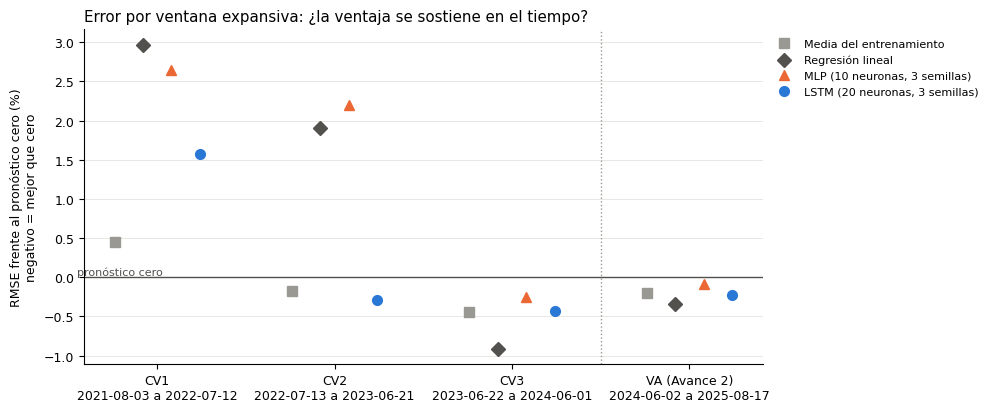

In [17]:
# === 4.2 Gráfica: RMSE de cada modelo frente al pronóstico cero, por ventana ===
from matplotlib.ticker import MaxNLocator
TINTA2, AZUL, NARANJA, GRIS, REJILLA = '#52514e', '#2a78d6', '#eb6834', '#9a9893', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': REJILLA, 'grid.linewidth': 0.6, 'font.size': 9})
ESTILO = {'media_entrenamiento': (GRIS, 's', 'Media del entrenamiento'),
          'regresion_lineal': (TINTA2, 'D', 'Regresión lineal'),
          'mlp_ensamble3': (NARANJA, '^', f"MLP ({MEJOR_N['mlp']} neuronas, 3 semillas)"),
          'lstm_ensamble3': (AZUL, 'o', f"LSTM ({MEJOR_N['lstm']} neuronas, 3 semillas)")}
conjs = [f'CV{k}' for k in range(1, K + 1)] + ['VA']
piv = TODAS.pivot(index='conjunto', columns='modelo', values='RMSE_vs_cero_%').loc[conjs]
fig, ax = plt.subplots(figsize=(10, 4.2))
desp = np.linspace(-0.24, 0.24, len(ESTILO))
for (nombre, (color, marca, etiqueta)), dx in zip(ESTILO.items(), desp):
    if nombre in piv:
        ax.plot(np.arange(len(conjs)) + dx, piv[nombre].to_numpy(), marca, color=color, ms=7, label=etiqueta, ls='none')
ax.axhline(0, color=TINTA2, lw=1)
ax.text(-0.45, 0, 'pronóstico cero', va='bottom', ha='left', fontsize=8, color=TINTA2)
ax.axvline(K - 0.5, color=GRIS, ls=':', lw=1)
etiquetas = [f"{r['ventana']}\n{r['evaluado_desde']} a {r['evaluado_hasta']}" for _, r in CV_DESC.iterrows()]
etiquetas.append(f"VA (Avance 2)\n{VA.fecha_objetivo.min().date()} a {VA.fecha_objetivo.max().date()}")
ax.set_xticks(range(len(conjs)), etiquetas)
ax.set_ylabel('RMSE frente al pronóstico cero (%)\nnegativo = mejor que cero')
ax.set_title('Error por ventana expansiva: ¿la ventaja se sostiene en el tiempo?', loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax.grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap9_error_por_ventana.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# === 4.3 Seguimiento: ¿el resultado depende de un único periodo favorable? ===
ventanas_cv = [f'CV{k}' for k in range(1, K + 1)]
rp = f'{RED_PRINCIPAL}_ensamble3'
print(f'En las {K} ventanas expansivas dentro de TR:')
SEGUIMIENTO = {}
for nombre in ['regresion_lineal'] + [f'{r}_ensamble3' for r in CONFIG['REDES_CV']]:
    gana_cero = int((TABLA_RMSE.loc[ventanas_cv, nombre] < TABLA_RMSE.loc[ventanas_cv, 'cero']).sum())
    SEGUIMIENTO[nombre] = {'ventanas_mejor_que_cero_RMSE': gana_cero}
    print(f'  {nombre:20s} mejora al pronóstico cero (RMSE) en {gana_cero} de {K} ventanas')
for red in CONFIG['REDES_CV']:
    n = f'{red}_ensamble3'
    gana_lr = int((TABLA_RMSE.loc[ventanas_cv, n] < TABLA_RMSE.loc[ventanas_cv, 'regresion_lineal']).sum())
    gana_lr_mae = int((TABLA_MAE.loc[ventanas_cv, n] < TABLA_MAE.loc[ventanas_cv, 'regresion_lineal']).sum())
    SEGUIMIENTO[n].update({'ventanas_mejor_que_LR_RMSE': gana_lr, 'ventanas_mejor_que_LR_MAE': gana_lr_mae})
    print(f'  {n:20s} supera a la regresión lineal en RMSE en {gana_lr} de {K} y en MAE en {gana_lr_mae} de {K} ventanas')
rango = TODAS[TODAS.conjunto.isin(ventanas_cv)].groupby('modelo')['RMSE_vs_cero_%'].agg(['min', 'max'])
print('\nRango de la mejora frente a cero entre ventanas (% de RMSE):')
print(rango.loc[[m for m in ORDEN_MOD if m != 'cero']].round(2).to_string())
print('\nLectura: si un modelo solo gana en una ventana, o el signo de su ventaja cambia entre ventanas,')
print('su resultado depende de un periodo favorable y no de una relación estable.')
with open(DIRS['resultados'] / 'seguimiento_ventanas_cap9.json', 'w') as f:
    json.dump(SEGUIMIENTO, f, indent=2)

En las 3 ventanas expansivas dentro de TR:
  regresion_lineal     mejora al pronóstico cero (RMSE) en 1 de 3 ventanas
  lstm_ensamble3       mejora al pronóstico cero (RMSE) en 2 de 3 ventanas
  mlp_ensamble3        mejora al pronóstico cero (RMSE) en 1 de 3 ventanas
  lstm_ensamble3       supera a la regresión lineal en RMSE en 2 de 3 y en MAE en 2 de 3 ventanas
  mlp_ensamble3        supera a la regresión lineal en RMSE en 1 de 3 y en MAE en 1 de 3 ventanas

Rango de la mejora frente a cero entre ventanas (% de RMSE):
                      min   max
modelo                         
media_entrenamiento -0.45  0.46
regresion_lineal    -0.92  2.97
lstm_ensamble3      -0.43  1.58
mlp_ensamble3       -0.25  2.65

Lectura: si un modelo solo gana en una ventana, o el signo de su ventaja cambia entre ventanas,
su resultado depende de un periodo favorable y no de una relación estable.


## 5. Umbrales de pronóstico y regla de trading en VA

**Regla:** al cierre del día $t$, si el rendimiento estimado $\hat y_t$ **supera δ**, la señal es *comprar*. La posición de 100 % del capital se ejecuta en la **apertura de $t+1$**. En otro caso se queda en efectivo, o se vende en la apertura de $t+1$ si había posición.

**Umbrales candidatos (máximo cinco, positivos, definidos antes de mirar VA):** se usa la técnica estadística del libro, que es tomar cuantiles de una serie **del conjunto de entrenamiento**. Aquí son los cuantiles 10, 25, 50, 75 y 90 % de las **predicciones del propio modelo en TR**, conservando solo los positivos. Así los umbrales quedan en la escala de cada modelo. Se guardan en un archivo con fecha antes de simular VA.

**Criterio de elección (protocolo):** mayor rendimiento neto en VA; en empate, menor *drawdown*. El costo de 0.10 % se cobra al operar y **no** es el valor de δ.

**Reglas de simulación del protocolo:**
- Capital de 100,000 USDT, sin ventas en corto.
- Para la compra, el monto se calcula incluyendo el costo.
- Solo se cobra cuando cambia la posición; una compra y su venta generan dos cargos.
- El patrimonio se valora al cierre de cada día.
- Al final se liquida al último cierre cobrando la venta.
- Se compara con efectivo y con comprar y mantener desde la misma primera fecha de ejecución, con costos equivalentes.

> Un umbral **no** equivale a una probabilidad de acierto: solo filtra pronósticos de baja magnitud.

In [19]:
# === 5. Motor de simulación (reglas del protocolo) ===
PRECIOS = datos.set_index('fecha')[['open', 'close']].astype(float)

def simular(fechas_ejecucion, senales, costo=None, capital=None):
    '''senales[i] = 1 (comprar) o 0 (efectivo), emitida al cierre del día anterior a fechas_ejecucion[i].
    Se ejecuta en la apertura de fechas_ejecucion[i] y el patrimonio se valora a su cierre.'''
    costo = CONFIG['COSTO'] if costo is None else costo
    capital = CONFIG['CAPITAL_INICIAL'] if capital is None else capital
    fechas = pd.DatetimeIndex(pd.to_datetime(fechas_ejecucion))
    senales = np.asarray(senales).astype(int)
    if len(fechas) == 0:
        raise DatosVaciosError('No hay fechas para simular.')
    if len(fechas) != len(senales):
        raise DimensionError(f'{len(fechas)} fechas y {len(senales)} señales.')
    if fechas.duplicated().any() or not fechas.is_monotonic_increasing:
        raise FechaDuplicadaError('Las fechas de ejecución deben ser únicas y crecientes.')
    faltan = fechas.difference(PRECIOS.index)
    if len(faltan):
        raise DatosVaciosError(f'Sin precio de apertura/cierre para {len(faltan)} fechas, ej. {faltan[:3].date.tolist()}')
    if not set(np.unique(senales)) <= {0, 1}:
        raise ValorInvalidoError('Las señales deben ser 0 o 1.')
    p = PRECIOS.loc[fechas]
    efectivo, unidades, base, costos_tot = float(capital), 0.0, 0.0, 0.0
    filas, cerradas = [], []
    for f, s, o, c in zip(fechas, senales, p['open'].to_numpy(), p['close'].to_numpy()):
        cargo, accion = 0.0, 'mantener'
        if s == 1 and unidades == 0:
            monto = efectivo / (1 + costo)
            cargo = monto * costo
            unidades, base, efectivo, accion = monto / o, efectivo, 0.0, 'compra'
        elif s == 0 and unidades > 0:
            bruto = unidades * o
            cargo = bruto * costo
            efectivo, accion = bruto - cargo, 'venta'
            cerradas.append(efectivo - base)
            unidades = 0.0
        costos_tot += cargo
        filas.append({'fecha': f.date(), 'precio_ejecucion': o, 'senal': 'comprar' if s else 'efectivo', 'accion': accion,
                      'posicion_unidades': unidades, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c,
                      'patrimonio': efectivo + unidades * c})
    if unidades > 0:                       # liquidación final al último cierre
        bruto = unidades * c
        cargo = bruto * costo
        efectivo = bruto - cargo
        cerradas.append(efectivo - base)
        costos_tot += cargo
        unidades = 0.0
        filas.append({'fecha': f.date(), 'precio_ejecucion': c, 'senal': 'liquidación', 'accion': 'venta final al cierre',
                      'posicion_unidades': 0.0, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c, 'patrimonio': efectivo})
    sim = pd.DataFrame(filas)
    patrimonio = np.r_[capital, sim['patrimonio'].to_numpy()]
    dd = patrimonio / np.maximum.accumulate(patrimonio) - 1
    resumen = {'patrimonio_final': float(efectivo), 'rendimiento_neto': float(efectivo / capital - 1),
               'max_drawdown': float(dd.min()), 'operaciones_cerradas': len(cerradas),
               'transacciones': int((sim['costo'] > 0).sum()),
               'win_rate': (float(np.mean(np.array(cerradas) > 0)) if cerradas else np.nan),
               'costos_totales': float(costos_tot), 'dias_en_mercado_%': float(100 * senales.mean()),
               'primera_ejecucion': fechas[0].date(), 'ultima_valoracion': fechas[-1].date()}
    return resumen, sim

# Prueba de escritorio del motor: comprar el día 1 y vender el día 3 (cifras verificables a mano)
f3 = VA['fecha_objetivo'].iloc[:3]
r_prueba, s_prueba = simular(f3, [1, 1, 0])
o1, o3 = PRECIOS.loc[f3.iloc[0], 'open'], PRECIOS.loc[f3.iloc[2], 'open']
esperado = CONFIG['CAPITAL_INICIAL'] / (1 + CONFIG['COSTO']) / o1 * o3 * (1 - CONFIG['COSTO'])
if not np.isclose(r_prueba['patrimonio_final'], esperado) or r_prueba['operaciones_cerradas'] != 1:
    raise ValorInvalidoError('El motor de simulación no reproduce el cálculo manual.')
print(f'✔ Prueba de escritorio: 100,000/(1+0.001)/{o1:,.2f}×{o3:,.2f}×(1−0.001) = {esperado:,.2f} = {r_prueba["patrimonio_final"]:,.2f}')
s_prueba

✔ Prueba de escritorio: 100,000/(1+0.001)/67,766.84×68,809.89×(1−0.001) = 101,336.30 = 101,336.30


,fecha,precio_ejecucion,senal,accion,posicion_unidades,efectivo,costo,precio_cierre,patrimonio
0,2024-06-02,67766.84,comprar,compra,1.474174,0.000000,99.900100,67765.63,99898.316150
1,2024-06-03,67765.63,comprar,mantener,1.474174,0.000000,0.000000,68809.89,101437.736880
2,2024-06-04,68809.89,efectivo,venta,0.000000,101336.299143,101.437737,70537.83,101336.299143


In [20]:
# === 5.1 Umbrales candidatos (definidos con TR, antes de simular VA) ===
def candidatos_umbral(pred_tr):
    q = np.quantile(pred_tr, CONFIG['CUANTILES_UMBRAL'])
    positivos = sorted({round(float(v), 6) for v in q if v > 0})
    return (positivos or list(CONFIG['UMBRALES_RESPALDO']))[:5], q

MODELOS_REGLA = [RED_PRINCIPAL, 'regresion_lineal']
CANDIDATOS, REG_CAND = {}, {}
for m in MODELOS_REGLA:
    CANDIDATOS[m], q = candidatos_umbral(PRED8[m]['TR'])
    REG_CAND[m] = {'cuantiles': CONFIG['CUANTILES_UMBRAL'], 'valores_cuantiles_TR': [float(v) for v in q],
                   'umbrales_candidatos': CANDIDATOS[m]}
REG_CAND['datos_usados'] = 'predicciones de cada modelo en TR (sin VA ni TE)'
REG_CAND['fecha_registro_utc'] = datetime.now(timezone.utc).isoformat(timespec='seconds')
with open(DIRS['resultados'] / 'umbrales_candidatos_cap9.json', 'w') as f:
    json.dump(REG_CAND, f, indent=2)
for m in MODELOS_REGLA:
    print(f"{m:18s} δ candidatos = {[f'{d:.4%}' for d in CANDIDATOS[m]]}")

lstm               δ candidatos = ['0.1374%', '0.1613%', '0.1929%', '0.2267%', '0.2964%']
regresion_lineal   δ candidatos = ['0.1596%', '0.3995%', '0.6494%']


In [21]:
# === 5.2 Simulación en VA de cada umbral y selección ===
FECHAS_VA = VA['fecha_objetivo']
BH, SIM_BH = simular(FECHAS_VA, np.ones(len(VA), int))
EF, _ = simular(FECHAS_VA, np.zeros(len(VA), int))
BH0, _ = simular(FECHAS_VA, np.ones(len(VA), int), costo=0.0)

filas_u, SIMS = [], {}
for m in MODELOS_REGLA:
    for d in CANDIDATOS[m]:
        senal = (PRED8[m]['VA'] > d).astype(int)
        res, sim = simular(FECHAS_VA, senal)
        res0, _ = simular(FECHAS_VA, senal, costo=0.0)
        SIMS[(m, d)] = sim
        filas_u.append({'modelo': m, 'delta': d, **res, 'rendimiento_neto_sin_costos': res0['rendimiento_neto']})
UMBRALES = pd.DataFrame(filas_u)
UMBRALES = pd.concat([UMBRALES, pd.DataFrame([{'modelo': nombre, 'delta': np.nan, **r, 'rendimiento_neto_sin_costos': r0['rendimiento_neto']}
                                               for nombre, r, r0 in (('comprar y mantener', BH, BH0), ('efectivo', EF, EF))])],
                     ignore_index=True)
UMBRALES.to_csv(DIRS['resultados'] / 'umbrales_probados_cap9_VA.csv', index=False)

def elegir(df):
    'Mayor rendimiento neto; en empate (diferencia < 1e-8), menor drawdown.'
    df = df.assign(_r=df['rendimiento_neto'].round(8))
    return df.sort_values(['_r', 'max_drawdown'], ascending=[False, False]).iloc[0]

ELEGIDO = {m: elegir(UMBRALES[UMBRALES.modelo == m]) for m in MODELOS_REGLA}
vista = UMBRALES.copy()
for c in ['delta', 'rendimiento_neto', 'max_drawdown', 'win_rate', 'rendimiento_neto_sin_costos']:
    vista[c] = vista[c].map(lambda v: '' if pd.isna(v) else f'{v:.2%}' if c != 'delta' else f'{v:.4%}')
vista['costos_totales'] = UMBRALES['costos_totales'].round(2)
vista['dias_en_mercado_%'] = UMBRALES['dias_en_mercado_%'].round(1)
vista[['modelo', 'delta', 'dias_en_mercado_%', 'operaciones_cerradas', 'rendimiento_neto', 'max_drawdown',
       'win_rate', 'costos_totales', 'patrimonio_final', 'rendimiento_neto_sin_costos']]

,modelo,delta,dias_en_mercado_%,operaciones_cerradas,rendimiento_neto,max_drawdown,win_rate,costos_totales,patrimonio_final,rendimiento_neto_sin_costos
0,lstm,0.1374%,87.6,28,79.73%,-27.99%,39.29%,7665.56,179734.237665,90.09%
1,lstm,0.1613%,66.5,66,15.51%,-34.97%,43.94%,14433.27,115508.841040,31.81%
2,lstm,0.1929%,36.9,62,-3.94%,-35.72%,41.94%,13261.30,96063.153353,8.75%
3,lstm,0.2267%,11.3,27,17.62%,-12.38%,59.26%,5789.11,117616.956984,24.14%
4,lstm,0.2964%,3.8,11,-6.01%,-20.00%,54.55%,2031.25,93993.882226,-3.92%
5,regresion_lineal,0.1596%,51.4,115,8.85%,-22.06%,49.57%,22239.23,108846.934646,36.99%
6,regresion_lineal,0.3995%,18.1,65,-3.12%,-23.14%,50.77%,12516.12,96883.872822,10.33%
7,regresion_lineal,0.6494%,4.3,18,14.25%,-3.32%,55.56%,3933.60,114249.483386,18.44%
8,comprar y mantener,,100.0,1,72.91%,-28.10%,100.00%,272.98,172906.408209,73.25%
9,efectivo,,0.0,0,0.00%,0.00%,,0.00,100000.000000,0.00%


In [22]:
# === 5.3 Regla seleccionada ===
sel = ELEGIDO[RED_PRINCIPAL]
ref = ELEGIDO['regresion_lineal']
REGLA = {
    'modelo': f'{RED_PRINCIPAL}_ensamble3', 'neuronas': MEJOR_N[RED_PRINCIPAL], 'semillas': SEMILLAS,
    'delta': float(sel['delta']),
    'regla': f'Si el rendimiento estimado al cierre de t supera δ = {sel["delta"]:.4%}, mantener 100 % comprado desde la '
             'apertura de t+1; en otro caso, efectivo (o vender en la apertura de t+1).',
    'criterio': 'Mayor rendimiento neto en VA con costo de 0.10 % por compra y por venta; en empate, menor drawdown.',
    'candidatos': CANDIDATOS[RED_PRINCIPAL], 'origen_candidatos': 'cuantiles de las predicciones del modelo en TR',
    'resultado_VA': {k: (float(sel[k]) if isinstance(sel[k], (int, float, np.floating, np.integer)) else str(sel[k]))
                     for k in ['rendimiento_neto', 'max_drawdown', 'operaciones_cerradas', 'win_rate', 'costos_totales',
                               'dias_en_mercado_%', 'patrimonio_final', 'rendimiento_neto_sin_costos']},
    'comprar_y_mantener_VA': {'rendimiento_neto': BH['rendimiento_neto'], 'max_drawdown': BH['max_drawdown']},
    'regresion_lineal_mejor_delta_VA': {'delta': float(ref['delta']), 'rendimiento_neto': float(ref['rendimiento_neto']),
                                        'max_drawdown': float(ref['max_drawdown'])},
    'nota': 'Un umbral no equivale a una probabilidad de acierto. TE no intervino en la elección.',
    'fecha_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS['resultados'] / 'regla_seleccionada_cap9.json', 'w') as f:
    json.dump(REGLA, f, indent=2, ensure_ascii=False, default=str)
SIM_SEL = SIMS[(RED_PRINCIPAL, sel['delta'])]
SIM_SEL.to_csv(DIRS['resultados'] / 'simulacion_VA_cap9.csv', index=False)

print(f"Regla seleccionada con VA: {RED_PRINCIPAL.upper()} (ensamble) con δ = {sel['delta']:.4%}")
print(f"  VA: rendimiento neto {sel['rendimiento_neto']:+.2%} | drawdown {sel['max_drawdown']:.2%} | "
      f"{int(sel['operaciones_cerradas'])} operaciones cerradas | {sel['dias_en_mercado_%']:.1f}% de días en el mercado | "
      f"costos {sel['costos_totales']:,.2f} USDT")
print(f"  Comprar y mantener en VA: {BH['rendimiento_neto']:+.2%} (drawdown {BH['max_drawdown']:.2%}) | Efectivo: 0.00%")
print(f"  Regresión lineal, su mejor δ ({ref['delta']:.4%}): {ref['rendimiento_neto']:+.2%} (drawdown {ref['max_drawdown']:.2%})")
print(f"  ¿Supera la regla de la red a la de la regresión lineal en VA? {'sí' if sel['rendimiento_neto'] > ref['rendimiento_neto'] else 'no'}")
print(f"  ¿Supera a comprar y mantener en VA? {'sí' if sel['rendimiento_neto'] > BH['rendimiento_neto'] else 'no'}")
if sel['dias_en_mercado_%'] in (0.0, 100.0):
    print('  AVISO: la regla está siempre fuera o siempre dentro del mercado: el umbral no está filtrando nada '
          '(la predicción es casi constante). Documenten esto como limitación.')

Regla seleccionada con VA: LSTM (ensamble) con δ = 0.1374%
  VA: rendimiento neto +79.73% | drawdown -27.99% | 28 operaciones cerradas | 87.6% de días en el mercado | costos 7,665.56 USDT
  Comprar y mantener en VA: +72.91% (drawdown -28.10%) | Efectivo: 0.00%
  Regresión lineal, su mejor δ (0.6494%): +14.25% (drawdown -3.32%)
  ¿Supera la regla de la red a la de la regresión lineal en VA? sí
  ¿Supera a comprar y mantener en VA? sí


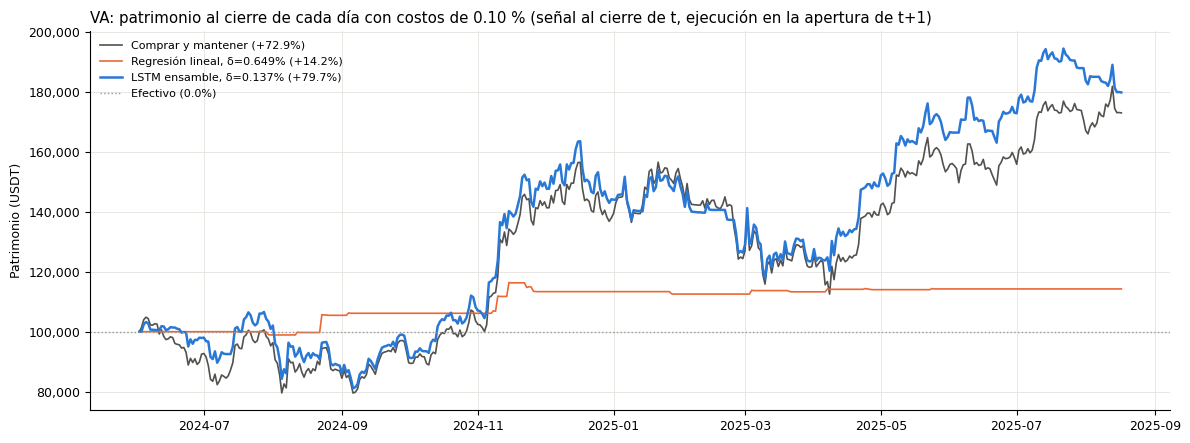

In [23]:
# === 5.4 Patrimonio en VA ===
fig, ax = plt.subplots(figsize=(12, 4.5))
def curva(sim):
    s = sim.groupby('fecha')['patrimonio'].last()
    return pd.to_datetime(s.index), s.to_numpy()
x, y = curva(SIM_BH)
ax.plot(x, y, color=TINTA2, lw=1.2, label=f"Comprar y mantener ({BH['rendimiento_neto']:+.1%})")
x, y = curva(SIMS[('regresion_lineal', ref['delta'])])
ax.plot(x, y, color=NARANJA, lw=1.2, label=f"Regresión lineal, δ={ref['delta']:.3%} ({ref['rendimiento_neto']:+.1%})")
x, y = curva(SIM_SEL)
ax.plot(x, y, color=AZUL, lw=1.8, label=f"{RED_PRINCIPAL.upper()} ensamble, δ={sel['delta']:.3%} ({sel['rendimiento_neto']:+.1%})")
ax.axhline(CONFIG['CAPITAL_INICIAL'], color=GRIS, ls=':', lw=1, label='Efectivo (0.0%)')
ax.set_ylabel('Patrimonio (USDT)')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title('VA: patrimonio al cierre de cada día con costos de 0.10 % (señal al cierre de t, ejecución en la apertura de t+1)', loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap9_patrimonio_VA.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.5 Robustez: la regla elegida en los bloques de las ventanas expansivas

Para responder si el resultado depende de un único periodo, se aplica **la misma regla y el mismo δ** a los pronósticos fuera de muestra de cada ventana expansiva, hechos por los modelos reentrenados en cada ventana. Es solo una comprobación: no se usa para elegir nada.

In [24]:
# === 5.5 Regla elegida en cada bloque de las ventanas ===
filas_rob = []
if f'{RED_PRINCIPAL}_ensamble3' in CV_PRED[1]['pred']:
    for k in range(1, K + 1):
        ev, p = CV_PRED[k]['eval'], CV_PRED[k]['pred'][f'{RED_PRINCIPAL}_ensamble3']
        res, _ = simular(ev['fecha_objetivo'], (p > REGLA['delta']).astype(int))
        bh, _ = simular(ev['fecha_objetivo'], np.ones(len(ev), int))
        filas_rob.append({'bloque': f'CV{k}', 'desde': ev.fecha_objetivo.min().date(), 'hasta': ev.fecha_objetivo.max().date(),
                          'regla_rend_neto': res['rendimiento_neto'], 'regla_drawdown': res['max_drawdown'],
                          'regla_dias_mercado_%': res['dias_en_mercado_%'], 'regla_operaciones': res['operaciones_cerradas'],
                          'BH_rend_neto': bh['rendimiento_neto'], 'BH_drawdown': bh['max_drawdown'],
                          'regla_supera_BH': res['rendimiento_neto'] > bh['rendimiento_neto']})
filas_rob.append({'bloque': 'VA', 'desde': VA.fecha_objetivo.min().date(), 'hasta': VA.fecha_objetivo.max().date(),
                  'regla_rend_neto': float(sel['rendimiento_neto']), 'regla_drawdown': float(sel['max_drawdown']),
                  'regla_dias_mercado_%': float(sel['dias_en_mercado_%']), 'regla_operaciones': int(sel['operaciones_cerradas']),
                  'BH_rend_neto': BH['rendimiento_neto'], 'BH_drawdown': BH['max_drawdown'],
                  'regla_supera_BH': float(sel['rendimiento_neto']) > BH['rendimiento_neto']})
ROBUSTEZ = pd.DataFrame(filas_rob)
ROBUSTEZ.to_csv(DIRS['resultados'] / 'robustez_regla_cap9.csv', index=False)
n_sup = int(ROBUSTEZ['regla_supera_BH'].sum())
print(f'La regla supera a comprar y mantener en {n_sup} de {len(ROBUSTEZ)} periodos.')
v = ROBUSTEZ.copy()
for c in ['regla_rend_neto', 'regla_drawdown', 'BH_rend_neto', 'BH_drawdown']:
    v[c] = v[c].map('{:+.2%}'.format)
v

La regla supera a comprar y mantener en 2 de 4 periodos.


,bloque,desde,hasta,regla_rend_neto,regla_drawdown,regla_dias_mercado_%,regla_operaciones,BH_rend_neto,BH_drawdown,regla_supera_BH
0,CV1,2021-08-03,2022-07-12,-29.30%,-57.94%,53.197674,42,-50.70%,-71.91%,True
1,CV2,2022-07-13,2023-06-21,+13.70%,-28.04%,38.372093,31,+54.84%,-35.45%,False
2,CV3,2023-06-22,2024-06-01,+29.23%,-19.13%,41.907514,35,+125.48%,-20.13%,False
3,VA,2024-06-02,2025-08-17,+79.73%,-27.99%,87.556561,28,+72.91%,-28.10%,True


## 6. Diferenciación fraccionaria

**Propósito (capítulo 9; López de Prado).** Una serie de precios no es estacionaria. Si se diferencia con orden 1 (rendimientos), se vuelve estacionaria pero pierde casi toda su **memoria**, es decir, la información del nivel del precio. La diferenciación fraccionaria usa un orden $d$ entre 0 y 1: aplica una suma ponderada de rezagos con pesos $w_0 = 1$ y $w_k = -w_{k-1}\,\frac{d-k+1}{k}$. Busca el **menor $d$** que logra estacionariedad, conservando la mayor parte posible de la memoria.

**¿Es pertinente para nuestras variables?**
- Las entradas actuales son rendimientos ($d = 1$) y ya son estacionarias: la prueba ADF del Avance 1 dio p ≈ 0. Para ellas **no hace falta**.
- Sería pertinente si quisieran agregar una variable con **memoria del nivel del precio** (por ejemplo, en el capítulo 11) sin romper la estacionariedad.
- Su utilidad debe comprobarse con VA, como cualquier variable nueva.

Abajo, como ampliación opcional, se busca el menor $d$ estacionario para el logaritmo del precio, **usando solo fechas de TR**. Se usa la versión de ventana fija (pesos menores a $10^{-4}$ se descartan), que solo usa información pasada.

Menor d estacionario en TR: d = 0.4 (p = 0.0076), correlación con el log-precio = 0.71 (con d = 1, rendimientos: 0.02)


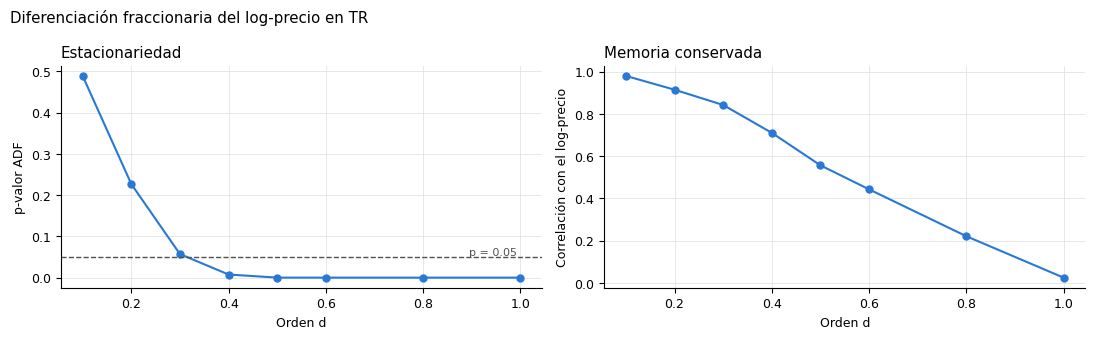

     d  pesos_usados  p_valor_ADF  estacionaria_5%  correlacion_con_log_precio
0  0.1           503       0.4892            False                      0.9799
1  0.2           497       0.2270            False                      0.9145
2  0.3           388       0.0571            False                      0.8423
3  0.4           282       0.0076             True                      0.7104
4  0.5           200       0.0000             True                      0.5565
5  0.6           140       0.0000             True                      0.4429
6  0.8            64       0.0000             True                      0.2209
7  1.0             2       0.0000             True                      0.0249


In [25]:
# === 6. Diferenciación fraccionaria (opcional, solo TR) ===
def pesos_ffd(d, umbral=1e-4, max_k=1000):
    w = [1.0]
    for k in range(1, max_k):
        wk = -w[-1] * (d - k + 1) / k
        if abs(wk) < umbral:
            break
        w.append(wk)
    return np.array(w)

def frac_diff(serie, d):
    w = pesos_ffd(d)
    if len(w) >= len(serie):
        raise DatosVaciosError(f'd={d}: la ventana de pesos ({len(w)}) no cabe en la serie ({len(serie)}).')
    return np.convolve(serie, w, mode='valid'), len(w)      # convolución = suma ponderada de valores pasados

if CONFIG['FRACDIFF_OPCIONAL']:
    from statsmodels.tsa.stattools import adfuller
    import warnings
    fin_tr_fecha = TR['fecha_objetivo'].max()
    log_p = np.log(datos.loc[datos.fecha <= fin_tr_fecha, 'close'].to_numpy(float))
    filas_fd = []
    for d in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]:
        try:
            fd, ancho = frac_diff(log_p, d)
        except DatosVaciosError as e:
            print('  ', e)
            continue
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            pval = adfuller(fd, autolag='AIC')[1]
        corr = np.corrcoef(fd, log_p[ancho - 1:])[0, 1]
        filas_fd.append({'d': d, 'pesos_usados': ancho, 'p_valor_ADF': pval, 'estacionaria_5%': pval < 0.05,
                         'correlacion_con_log_precio': corr})
    FD = pd.DataFrame(filas_fd)
    FD.to_csv(DIRS['resultados'] / 'diferenciacion_fraccionaria_TR_cap9.csv', index=False)
    est = FD[FD['estacionaria_5%']]
    if len(est):
        dmin = est.iloc[0]
        print(f"Menor d estacionario en TR: d = {dmin['d']} (p = {dmin['p_valor_ADF']:.4f}), "
              f"correlación con el log-precio = {dmin['correlacion_con_log_precio']:.2f} "
              f"(con d = 1, rendimientos: {FD[FD.d == 1.0]['correlacion_con_log_precio'].iloc[0]:.2f})")
    else:
        print('Ningún d probado logra estacionariedad al 5 %.')

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].plot(FD['d'], FD['p_valor_ADF'], 'o-', color=AZUL, ms=5)
    axes[0].axhline(0.05, color=TINTA2, ls='--', lw=1)
    axes[0].text(FD['d'].max(), 0.05, 'p = 0.05 ', ha='right', va='bottom', fontsize=8, color=TINTA2)
    axes[0].set_xlabel('Orden d'); axes[0].set_ylabel('p-valor ADF'); axes[0].set_title('Estacionariedad', loc='left')
    axes[1].plot(FD['d'], FD['correlacion_con_log_precio'], 'o-', color=AZUL, ms=5)
    axes[1].set_xlabel('Orden d'); axes[1].set_ylabel('Correlación con el log-precio'); axes[1].set_title('Memoria conservada', loc='left')
    fig.suptitle('Diferenciación fraccionaria del log-precio en TR', x=0.01, ha='left')
    fig.tight_layout()
    fig.savefig(DIRS['figuras'] / 'cap9_diferenciacion_fraccionaria.png', dpi=150, bbox_inches='tight')
    plt.show()
    display(FD.round(4)) if 'display' in globals() else print(FD.round(4))

## 7. Comprobación: TE no intervino en ninguna decisión

In [26]:
# === 7. Trazabilidad de decisiones y controles finales ===
DECISIONES = pd.DataFrame([
    ('Escaladores de X y de y (modelos finales)', 'TR', 'Avances 1 y 2'),
    ('Escaladores en cada ventana expansiva', 'Entrenamiento de esa ventana (dentro de TR)', 'Avance 3'),
    ('Época de parada en cada ventana', 'Validación interna = último 15 % del entrenamiento de la ventana', 'Avance 3'),
    ('Arquitectura y número de neuronas', 'VA', 'Avance 2'),
    ('Umbrales candidatos δ', 'Predicciones del modelo en TR', 'Avance 3'),
    ('Umbral elegido δ', 'VA (rendimiento neto; empate: drawdown)', 'Avance 3'),
    ('Robustez de la regla', 'Bloques de TR (solo comprobación)', 'Avance 3'),
    ('Diferenciación fraccionaria', 'TR (solo exploración)', 'Avance 3'),
], columns=['decision', 'datos_usados', 'avance'])
DECISIONES.to_csv(DIRS['resultados'] / 'trazabilidad_decisiones_cap9.csv', index=False)

controles = {
    'T4 verificada': bool(EVIDENCIA_T4.get('T4_OK')),
    'Ventanas: entrenamiento termina antes del bloque evaluado': all(
        TR.iloc[:fe]['fecha_objetivo'].max() < TR.iloc[fe:fv]['fecha_objetivo'].min() for _, fe, fv in VENTANAS),
    'Ventanas: bloques evaluados dentro de TR': all(fv <= len(TR) for *_, fv in VENTANAS),
    'Tres ventanas expansivas con error reportado': CV['conjunto'].nunique() == K == 3,
    'Entrenamientos de ventanas con pesos en GPU': all('GPU' in i['dispositivo_pesos'].upper() for i in CV_INFO),
    'Hasta cinco umbrales por modelo, positivos': all(0 < len(v) <= 5 and min(v) > 0 for v in CANDIDATOS.values()),
    'Umbrales registrados antes de simular VA': (DIRS['resultados'] / 'umbrales_candidatos_cap9.json').exists(),
    'Conjuntos sobre los que se predijo': ', '.join(sorted(CONJUNTOS_PREDICHOS)),
    'TE nunca se predijo ni se simuló': 'TE' not in CONJUNTOS_PREDICHOS and
        SIM_SEL['fecha'].max() < TE['fecha_objetivo'].min().date(),
}
for k, v in controles.items():
    print(('✔' if v is True else '✘' if v is False else '•'), k, '' if isinstance(v, bool) else f': {v}')
if 'TE' in CONJUNTOS_PREDICHOS:
    raise FugaInformacionError('Se predijo sobre TE: revisar antes de continuar.')
with open(DIRS['resultados'] / 'controles_cap9.json', 'w') as f:
    json.dump(controles, f, indent=2, ensure_ascii=False, default=str)
DECISIONES

✔ T4 verificada 
✔ Ventanas: entrenamiento termina antes del bloque evaluado 
✔ Ventanas: bloques evaluados dentro de TR 
✔ Tres ventanas expansivas con error reportado 
✔ Entrenamientos de ventanas con pesos en GPU 
✔ Hasta cinco umbrales por modelo, positivos 
✔ Umbrales registrados antes de simular VA 
• Conjuntos sobre los que se predijo : CV1, CV2, CV3, TR, VA
✔ TE nunca se predijo ni se simuló 


,decision,datos_usados,avance
0,Escaladores de X y de y (modelos finales),TR,Avances 1 y 2
1,Escaladores en cada ventana expansiva,Entrenamiento de esa ventana (dentro de TR),Avance 3
2,Época de parada en cada ventana,Validación interna = último 15 % del entrenamiento de la ventana,Avance 3
3,Arquitectura y número de neuronas,VA,Avance 2
4,Umbrales candidatos δ,Predicciones del modelo en TR,Avance 3
5,Umbral elegido δ,VA (rendimiento neto; empate: drawdown),Avance 3
6,Robustez de la regla,Bloques de TR (solo comprobación),Avance 3
7,Diferenciación fraccionaria,TR (solo exploración),Avance 3


## 1. Error por ventana

Los resultados muestran que ningún modelo mantiene un comportamiento estable en todas las ventanas evaluadas.

- En CV1, correspondiente al mercado bajista de 2021–2022, todos los modelos presentan un error mayor que el pronóstico cero.
- La LSTM mejora al pronóstico cero en dos de las tres ventanas y supera a la regresión lineal en dos de las tres, tanto en RMSE como en MAE.
- La regresión lineal únicamente mejora al pronóstico cero en CV3.
- Las ventajas de la LSTM son menores al 1.6 %, por lo que representan evidencia favorable, pero débil.

## 2. Selección de la regla de operación

La regla seleccionada fue la LSTM con un umbral de **δ = 0.1374 %**.

Los resultados obtenidos en validación (VA) fueron:

| Estrategia | Rendimiento neto | Drawdown |
|---|---:|---:|
| LSTM, δ = 0.1374 % | **+79.7 %** | -28.0 % |
| Comprar y mantener | +72.9 % | -28.1 % |
| Regresión lineal, su mejor δ | +14.2 % | -3.3 % |

La estrategia LSTM superó a la regresión lineal y a comprar y mantener durante el periodo de validación. Sin embargo, es importante considerar tres aspectos:

- La estrategia permanece dentro del mercado el 87.6 % de los días, por lo que su comportamiento es similar al de comprar y mantener. La ventaja de aproximadamente siete puntos porcentuales se debe a que logra evitar algunos días de caída.
- El resultado es sensible al umbral δ. Los cinco valores probados produjeron rendimientos de +79.7 %, +15.5 %, -3.9 %, +17.6 % y -6.0 %. No se observa un patrón consistente, por lo que seleccionar el mejor resultado entre cinco alternativas en VA puede generar una estimación optimista.
- El umbral no representa una probabilidad de acierto. El *win rate* de la regla seleccionada fue de 39 %.

## 3. Seguimiento: dependencia del periodo de mercado

Los resultados muestran que el desempeño de la estrategia depende de las condiciones del mercado.

| Periodo | Condición del mercado | Regla | Comprar y mantener |
|---|---|---:|---:|
| CV1 | Bajista | -29 % | -51 % |
| CV2 | Alcista | +14 % | +55 % |
| CV3 | Alcista | +29 % | +125 % |
| VA | Alcista | +80 % | +73 % |

La regla funciona principalmente como un mecanismo de reducción de exposición al mercado: ayuda a disminuir las pérdidas durante periodos bajistas, pero puede quedarse atrás durante periodos alcistas.

En los bloques de validación cruzada (CV), la estrategia permaneció dentro del mercado solamente entre el 38 % y el 53 % de los días. Además, un mismo umbral puede producir comportamientos diferentes dependiendo del modelo utilizado, lo que representa una limitación que debe considerarse.

## 4. Diferenciación fraccionaria

El menor orden de diferenciación que resultó estacionario en el conjunto de entrenamiento (TR) fue **d = 0.4**.

Este resultado conserva una correlación de 0.71 con el logaritmo del precio, mientras que los rendimientos presentan una correlación de 0.02.

La diferenciación fraccionaria podría ser una alternativa para incorporar información relacionada con la memoria del nivel del precio. Sin embargo, todavía no se utiliza en las entradas actuales de los modelos y sería necesario evaluar su utilidad incorporándola como una variable adicional y validándola con VA.

## 5. Advertencia para el conjunto de prueba (TE) y el objetivo de +20 %

Durante el periodo de prueba (TE), Bitcoin presentó una tendencia bajista. Debido a que la regla seleccionada permanece dentro del mercado el 87.6 % de los días, existe el riesgo de que también experimente pérdidas durante este periodo.

Los resultados de CV1 muestran que reducir la exposición al mercado puede ayudar durante periodos bajistas. Por ello, se plantea evaluar un filtro técnico basado en la media móvil simple de 20 días (SMA20), que permita mantener una posición de compra únicamente cuando el precio de cierre se encuentre por encima de dicha media.

Este filtro corresponde al protocolo del Avance 5 (capítulo 11) y deberá seleccionarse utilizando exclusivamente los resultados de validación (VA), antes de aplicarlo al conjunto de prueba (TE).

El objetivo de alcanzar un rendimiento de +20 % debe evaluarse considerando el riesgo, los periodos de exposición y los costos de operación, sin asumir que los resultados históricos garantizan rendimientos futuros.

## 6. Conclusión general

El Avance 3 permitió evaluar el comportamiento de los modelos mediante ventanas expansivas y estrategias de operación, comprobando que la LSTM puede ofrecer resultados favorables en determinados periodos, aunque su desempeño no es estable en todas las condiciones del mercado.

La estrategia seleccionada obtuvo un rendimiento neto de +79.7 % en validación, superando a comprar y mantener y a la regresión lineal. Sin embargo, su sensibilidad al umbral, su exposición al mercado y su bajo *win rate* muestran que todavía existen riesgos y limitaciones.

Como siguiente paso, se propone evaluar el filtro de la SMA20 establecido en el protocolo del Avance 5, utilizando validación para seleccionar sus parámetros y manteniendo el conjunto de prueba sin utilizar hasta la evaluación final.


## 8. Reflexión del capítulo 9

- **Qué hicimos:** Realizamos tres evaluaciones con ventanas expansivas dentro del conjunto de entrenamiento (TR), utilizando modelos de referencia, regresión lineal, MLP y LSTM. Posteriormente, definimos hasta cinco umbrales de pronóstico a partir de las predicciones de TR y seleccionamos una regla de operación utilizando el conjunto de validación (VA). También evaluamos la robustez de la estrategia en diferentes periodos del mercado y exploramos la diferenciación fraccionaria del logaritmo del precio de Bitcoin.

- **Por qué:** El objetivo fue comprobar si los modelos de Deep Learning mantienen su capacidad predictiva en diferentes periodos y si sus pronósticos pueden convertirse en señales de operación rentables. También buscamos evitar la fuga de información, asegurando que los entrenamientos y las decisiones se realizaran únicamente con información disponible en cada momento.

- **Evidencia obtenida:** La LSTM mejoró al pronóstico cero en 2 de las 3 ventanas expansivas y superó a la regresión lineal en 2 de las 3 ventanas, tanto en RMSE como en MAE. Sin embargo, las mejoras fueron pequeñas y ningún modelo mostró un desempeño estable en todos los periodos. En validación se seleccionó la LSTM con un umbral de δ = 0.1374 %, que obtuvo un rendimiento neto de 79.73 % y un drawdown de -27.99 %. Este resultado superó a comprar y mantener, que obtuvo 72.91 %, y a la regresión lineal, que alcanzó 14.25 % con su mejor umbral.

- **¿El resultado depende de un único periodo favorable?:** En parte, sí. Al aplicar la misma regla en los cuatro periodos evaluados, la estrategia superó a comprar y mantener solamente en 2 de 4 periodos. En CV1, durante el mercado bajista, obtuvo -29.30 %, frente a -50.70 % de comprar y mantener. En CV2 y CV3, ambos periodos alcistas, quedó por debajo de comprar y mantener. En VA consiguió 79.73 %, superando el 72.91 % de la estrategia de referencia. Esto indica que la regla funciona principalmente como un mecanismo de reducción de exposición al mercado y que sus resultados dependen de las condiciones del periodo evaluado.

- **¿TE intervino en alguna decisión?:** No. El conjunto de prueba (TE) permaneció reservado y no se utilizó para entrenar modelos, ajustar escaladores, seleccionar arquitecturas, establecer umbrales ni elegir la estrategia. Las decisiones se tomaron utilizando TR, las ventanas expansivas y VA, respetando la separación temporal de los datos.

- **Diferenciación fraccionaria: ¿es pertinente?:** Sí, podría ser pertinente para incorporar información del nivel del precio sin perder tanta memoria como sucede con la diferenciación tradicional. En la prueba realizada exclusivamente con TR, el menor orden que consiguió estacionariedad fue d = 0.4, con un p-valor ADF de 0.0076 y una correlación de 0.71 con el logaritmo del precio. En comparación, con d = 1 la correlación fue de aproximadamente 0.02. Sin embargo, las entradas actuales ya utilizan rendimientos estacionarios, por lo que la diferenciación fraccionaria sería una posible variable adicional para futuros modelos, cuya utilidad tendría que comprobarse en VA.

- **Qué cambiaríamos después:** Incorporaríamos indicadores técnicos, como medias móviles y volatilidad, para evaluar si aportan información adicional a los modelos. También probaríamos un filtro basado en la media móvil simple de 20 días (SMA20), que permita mantener una posición comprada únicamente cuando el precio de cierre esté por encima de dicha media. Esta estrategia se evaluaría utilizando VA antes de aplicarla al conjunto de prueba, considerando los costos de operación, el rendimiento neto y el riesgo de las inversiones.
